<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/22_Deepfake_Spoofing_Detection/HybridQNN_DeepfakeTrafficSign_Salek2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical NN for GAN deepfake traffic-sign detection: Salek et al. 2024 step by step

**Paper.** M. Sabbir Salek, Shaozhi Li, Mashrur Chowdhury, *A Hybrid Quantum-Classical AI-Based Detection Strategy for Generative Adversarial Network-Based Deepfake Attacks on an Autonomous Vehicle Traffic Sign Classification System*, TraCR / Clemson University, submitted to TRB 2025, arXiv:2409.17311 (2024). <https://arxiv.org/abs/2409.17311>

**What is the threat?** An autonomous vehicle (AV) reads traffic signs with a neural network. An attacker who sits between the camera and that network replaces the real sign image with a *GAN-generated fake* of a different sign (a stop sign becomes "speed limit 45"). It is *not* a CAN-bus attack and *not* a face deepfake: the target is a traffic-sign classifier. The defence is a second network that looks at the image and says "real" or "fake" before the AV trusts it.

**What this notebook does**
1. Downloads a public traffic-sign dataset (GTSRB, a substitute for the paper's LISA + Mapillary US signs).
2. Trains a WGAN-GP (DCGAN generator, WGAN critic) and runs the paper's latent-vector deepfake attack to create fake signs.
3. Trains a ResNet9 sign-type classifier that routes each image to a sign-type-specific detector.
4. Builds the quantum neural network of the paper in **PennyLane** (12 qubits, amplitude encoding, 32 circuits, quantum convolution and pooling layers), checks a fast torch re-implementation against PennyLane, and trains the hybrid detector.
5. Trains the five classical CNN baselines (CNN-1 ... CNN-5) on the same images and compares accuracy, F1 and parameter counts with the paper's Fig. 9 and Table 2.

**How to run.** Open in Google Colab (CPU runtime is enough), then *Runtime -> Run all*. `FAST_MODE = True` (two sign types, tiny budgets) finishes in about 10 minutes on a CPU; `FAST_MODE = False` runs all eight sign types with larger budgets (see "Reading the paper critically" for the measured runtime). Data and the trained generator are cached in `DATA_DIR`.

**What you get at the end:** a table of detection accuracy and F1 per sign type for the hybrid network and the five CNNs, the parameter-count table (Table 2 of the paper), and a claim-by-claim verdict "reproduced / not reached / cannot be checked".

## The paper in one page

* **Problem.** GAN-based deepfake attack on the traffic sign classifier of an AV (image replacement between camera and classifier).
* **Attack (Eq. 1-3, Figs. 1-3).** A WGAN-GP is trained on real sign images. For a real image *x* the attacker searches the latent vector *z\** = argmax ||G(z) - x||² by gradient ascent from a fixed number of random initialisations, so that G(z\*) looks as unlike *x* as possible (usually another sign type). 3 x 32 x 32 images.
* **Defence pipeline (Fig. 4).** (1) A ResNet9 classifier names the sign type (reported 0.97 precision / recall / F1 / accuracy on real + fake images). (2) A **sign-type-specific** detector decides real (0) or fake (1).
* **Detectors.** Five classical CNNs (1 to 5 blocks of Conv3x3 - BatchNorm - ReLU - MaxPool, dropout 0.2, one fully connected layer) and the **hybrid quantum-classical NN**: 32 quantum NNs give 32 neurons, a Tanh, a 120-neuron layer, one output. Each quantum NN uses **amplitude encoding** of the 3072 pixel values on 12 qubits, a rotation layer (Ry, Rz), a CNOT chain, three quantum-convolution and three quantum-pooling layers, and the readout is <Z> on the last qubit. Adam optimiser, PennyLane simulation, finite-difference gradients.
* **Data.** Ten US sign types from LISA and Mapillary, manually cleaned; 146 to 250 images per type (50 % real, 50 % fake), shuffled and split 60 / 20 / 20 into train / validation / test. Fake images the authors could not recognise as a sign were removed by hand.
* **Metrics.** Precision, recall, F1, accuracy per sign type (Fig. 9), parameter count and memory (Table 2: hybrid 5,425 parameters = 0.021 MB, less than one third of CNN-1 with 17,346).
* **Claims.** (a) Hybrid accuracy is similar or higher than the classical CNNs in most cases, with exceptions PED XING and SPEED LIMIT 45; (b) classical performance improves from CNN-1 to CNN-5; (c) the hybrid model needs under one third of the memory of the shallowest CNN; (d) the ResNet9 sign classifier reaches 0.97.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Real images | LISA + Mapillary US signs, 10 types, manual cleaning | **GTSRB** (German signs, public mirror on Hugging Face), 8 types: STOP, SIGNAL AHEAD (traffic signals), SCHOOL ZONE (children crossing), SPEED LIMIT 30/50/60/70/80 km/h. PED XING (only 6 physical signs in GTSRB-train) is dropped |
| Images per type | 146-250 real + fake | 160 (80 real + 80 fake) in the full run, 80 in FAST_MODE |
| Split | 60 / 20 / 20 random | 60 / 20 / 20, but real images are split **by physical sign (track)** so near-duplicate frames never cross splits |
| GAN | WGAN-GP, DCGAN generator, WGAN critic, lambda = 10 | same layout at **half channel width**; lr 2e-4, batch 32, 3 critic steps per generator step and the iteration count are `# CHOICE:` (paper silent, CPU budget); trained for 150 (FAST) / 1000 iterations, far below a production GAN, so the fakes are blurry |
| Attack | argmax ||G(z)-x||² from a fixed number of random z | 5 random starts, 3 Adam steps (lr 0.02), z kept on the sphere of typical N(0, I) vectors (`# CHOICE:`). Longer or larger steps push G(z) to all-white / all-black images, which maximise the distance but are not signs |
| Removing unrecognisable fakes | by hand | automatic: for each type keep the fakes that ResNet9 reads *as that type* (different from the input type) with the highest confidence; fakes are rounded to 8 bit like a saved image |
| ResNet9 | Fig. 5, full width | Fig. 5 layout at **half width** to save CPU time; trained on real train-track images only |
| Classical CNNs | channel widths not stated | widths 32, 64, 128, 256, 512 are the only ones that reproduce Table 2 exactly (checked below) |
| Hybrid NN | 32 circuits, 12 qubits, 5,425 parameters | identical; 42 parameters per circuit (24 rotation + 3 x 3 conv + 3 x 3 pool, shared inside a layer) + 3,960 + 121 = 5,425 |
| Gate pattern per layer | Fig. 7(b) drawn for 6 qubits | brickwork: gates on pairs (0,1),(2,3)... then (1,2),(3,4)... (`# CHOICE:` extended to 12 qubits) |
| Gradient | finite differences | exact back-propagation through a batched state-vector simulator, checked against PennyLane |
| Loss, epochs, learning rates, batch sizes | not stated | BCE for the hybrid, cross entropy for the CNNs, Adam, epochs 30 / 3 (FAST) or 30 / 6 (full), CNN / hybrid, best-validation epoch kept (`# CHOICE:`) |
| Seeds | not stated | classical CNNs: 1 seed (FAST) / 3 seeds (full); CNN batch 8, hybrid batch 8; hybrid: 1 seed (simulating 12 qubits x 32 circuits is slow) |

In [1]:

# Colab already ships torch, numpy, pandas, scikit-learn and matplotlib. We only add PennyLane and the HF client.
# The guard avoids reinstalling when the libraries are already importable (e.g. a local environment).
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("torch", "pennylane", "huggingface_hub", "pyarrow"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "pennylane==0.45.1", "huggingface_hub", "pyarrow"])
    print("Installed. If a later import fails, use Runtime -> Restart session and Run all again.")
else:
    print("All libraries already available, nothing to install.")


All libraries already available, nothing to install.


## 0. Configuration

Everything tunable is in this one cell. The paper's own budgets are unknown (epochs, learning rates), so they are marked `# CHOICE:`.

In [2]:

import os

SEED = 42                     # master seed (GAN, attack, ResNet9, data sampling)
FAST_MODE = False             # True: ~10 minute class demo; False: full run (see the timing note in the text)
DATA_DIR = "qc235_data"       # downloads and cached GAN weights go here
IBM_TOKEN = ""                # unused: this paper only needs a classical simulator (kept for template uniformity)
os.makedirs(DATA_DIR, exist_ok=True)

# CHOICE: the paper uses 10 US sign types from LISA + Mapillary (not downloadable here).
# We use the German GTSRB signs below (paper name -> GTSRB class id).
ALL_TYPES = {
    "STOP": 14,                # GTSRB "stop"
    "SIGNAL AHEAD": 26,        # GTSRB "traffic signals"
    "SCHOOL ZONE": 28,         # GTSRB "children crossing"
    "SPEED LIMIT 30": 1, "SPEED LIMIT 50": 2, "SPEED LIMIT 60": 3,
    "SPEED LIMIT 70": 4, "SPEED LIMIT 80": 5,   # km/h instead of mph; paper has 25/30/35/45/55 mph
}

if FAST_MODE:
    TYPES = ["STOP", "SPEED LIMIT 30"]
    POOL_PER_TYPE   = 120     # real images sampled per type (all tracks)
    N_PER_TYPE      = 80      # real + fake per type (paper: 146-250); 50 % real, 50 % fake
    GAN_ITERS       = 150     # generator updates (each = N_CRITIC critic updates)
    ATTACK_INPUTS   = 120     # real images per type fed to the attacker
    R9_EPOCHS       = 20
    CNN_EPOCHS      = 30
    Q_EPOCHS        = 3
    SEEDS_CLASSICAL = [0]
    SEEDS_HYBRID    = [0]
else:
    TYPES = list(ALL_TYPES)
    POOL_PER_TYPE   = 400
    N_PER_TYPE      = 160
    GAN_ITERS       = 1000
    ATTACK_INPUTS   = 400
    R9_EPOCHS       = 12
    CNN_EPOCHS      = 30
    Q_EPOCHS        = 6
    SEEDS_CLASSICAL = [0, 1, 2]
    SEEDS_HYBRID    = [0]

# ---- GAN (paper: WGAN-GP, lambda = 10, DCGAN generator, WGAN critic) ----
LATENT = 128; GAN_BATCH = 32; N_CRITIC = 3; LAMBDA_GP = 10.0; LR_GAN = 2e-4     # CHOICE: lr, batch, n_critic
GAN_WIDTH = 0.5               # CHOICE: half the channel widths of Figs. 2-3 (CPU time)
# ---- attack (paper: fixed number of random initialisations of z, gradient-based) ----
N_INIT = 5; ATTACK_STEPS = 3; ATTACK_LR = 0.02                                 # CHOICE
# ---- traffic sign classifier (paper: ResNet9) ----
R9_WIDTH = 0.5                                                                  # CHOICE: half width for CPU
# ---- classical CNN baselines ----
CNN_LR = 1e-3; CNN_BATCH = 8                                                    # CHOICE
# ---- hybrid quantum-classical NN (paper: 32 quantum circuits, 12 qubits, Adam) ----
N_QUBITS = 12; N_CIRCUITS = 32; Q_LR = 0.02; Q_BATCH = 8 if FAST_MODE else 4; Q_INIT_STD = 0.5       # CHOICE: lr, batch, init
SPLIT = (0.6, 0.2, 0.2)       # paper: 60 / 20 / 20 train / validation / test


## 0b. Imports, seeds, versions

In [3]:

import io, time, math, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from PIL import Image
from huggingface_hub import hf_hub_download
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix
warnings.filterwarnings("ignore")

torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.use_deterministic_algorithms(False)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| threads", torch.get_num_threads())
print("FAST_MODE =", FAST_MODE, "| types:", TYPES)
T_NOTEBOOK = time.time()


torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | threads 4
FAST_MODE = False | types: ['STOP', 'SIGNAL AHEAD', 'SCHOOL ZONE', 'SPEED LIMIT 30', 'SPEED LIMIT 50', 'SPEED LIMIT 60', 'SPEED LIMIT 70', 'SPEED LIMIT 80']


## 1. Data: real traffic signs

The paper's LISA and Mapillary traffic-sign images are not available without registration, so we use **GTSRB** (German Traffic Sign Recognition Benchmark) from a public Hugging Face mirror. Each physical sign was filmed as a track of 30 consecutive frames; we keep the track id so that all frames of one sign go to the same split (train / validation / test). Images are resized to 32 x 32 x 3 like in the paper.

In [4]:

def load_gtsrb():
    """Return (list of PNG bytes, label array, track-id array, source description)."""
    try:   # primary: 26,640 GTSRB training images, sorted by class, 30 consecutive frames per physical sign
        p = hf_hub_download("tanganke/gtsrb", "data/train-00000-of-00001.parquet", repo_type="dataset", local_dir=DATA_DIR)
        df = pd.read_parquet(p)
        labels = df["label"].to_numpy()
        track = np.arange(len(df)) // 30            # CHOICE: GTSRB tracks are 30 consecutive frames
        assert (labels.reshape(-1, 30) == labels.reshape(-1, 30)[:, :1]).all(), "unexpected track layout"
        return [d["bytes"] for d in df["image"]], labels, track, "tanganke/gtsrb (train, 26,640 images)"
    except Exception as e:                           # fallback: 39,209 images, shuffled -> no track information
        print("primary GTSRB mirror failed (", repr(e)[:80], ") -> fallback bazyl/GTSRB without track ids")
        p = hf_hub_download("bazyl/GTSRB", "data/train-00000-of-00001-dc762c064c221993.parquet", repo_type="dataset", local_dir=DATA_DIR)
        df = pd.read_parquet(p)
        labels = df["ClassId"].to_numpy()
        track = np.arange(len(df))                    # every image is its own group (near-duplicates may leak)
        return [d["bytes"] for d in df["Path"]], labels, track, "bazyl/GTSRB (train, 39,209 images, no track ids)"

png, labels, track, SRC = load_gtsrb()
print("source:", SRC, "| images:", len(png), "| tracks:", len(np.unique(track)))

def decode(b):   # CHOICE: bilinear resize to the 32 x 32 x 3 size used in the paper
    return np.asarray(Image.open(io.BytesIO(b)).convert("RGB").resize((32, 32), Image.BILINEAR), dtype=np.uint8)

POOL = {}        # type -> dict(img uint8 [n,32,32,3], part [n] in {0,1,2} = train/val/test by *track*)
for name in TYPES:
    idx = np.flatnonzero(labels == ALL_TYPES[name])
    idx = rng.choice(idx, size=min(POOL_PER_TYPE, len(idx)), replace=False)
    tr_ids = rng.permutation(np.unique(track[idx]))
    n = len(tr_ids); n_va = max(1, round(SPLIT[1] * n)); n_te = max(1, round(SPLIT[2] * n)); n_tr = n - n_va - n_te
    part_of = {t: (0 if i < n_tr else 1 if i < n_tr + n_va else 2) for i, t in enumerate(tr_ids)}
    POOL[name] = dict(img=np.stack([decode(png[i]) for i in idx]), part=np.array([part_of[track[i]] for i in idx]),
                      n_tracks=n)
del png
print(pd.DataFrame({k: {"GTSRB class": ALL_TYPES[k], "tracks": v["n_tracks"], "pool images": len(v["img"]),
                        "train/val/test images": tuple(int((v["part"] == p).sum()) for p in range(3))} for k, v in POOL.items()}).T)


source: tanganke/gtsrb (train, 26,640 images) | images: 26640 | tracks: 888


               GTSRB class tracks pool images train/val/test images
STOP                    14     18         400         (226, 87, 87)
SIGNAL AHEAD            26     14         400         (226, 85, 89)
SCHOOL ZONE             28     12         360         (240, 60, 60)
SPEED LIMIT 30           1     50         400         (251, 73, 76)
SPEED LIMIT 50           2     50         400         (239, 73, 88)
SPEED LIMIT 60           3     32         400         (245, 82, 73)
SPEED LIMIT 70           4     44         400         (243, 78, 79)
SPEED LIMIT 80           5     42         400         (250, 86, 64)


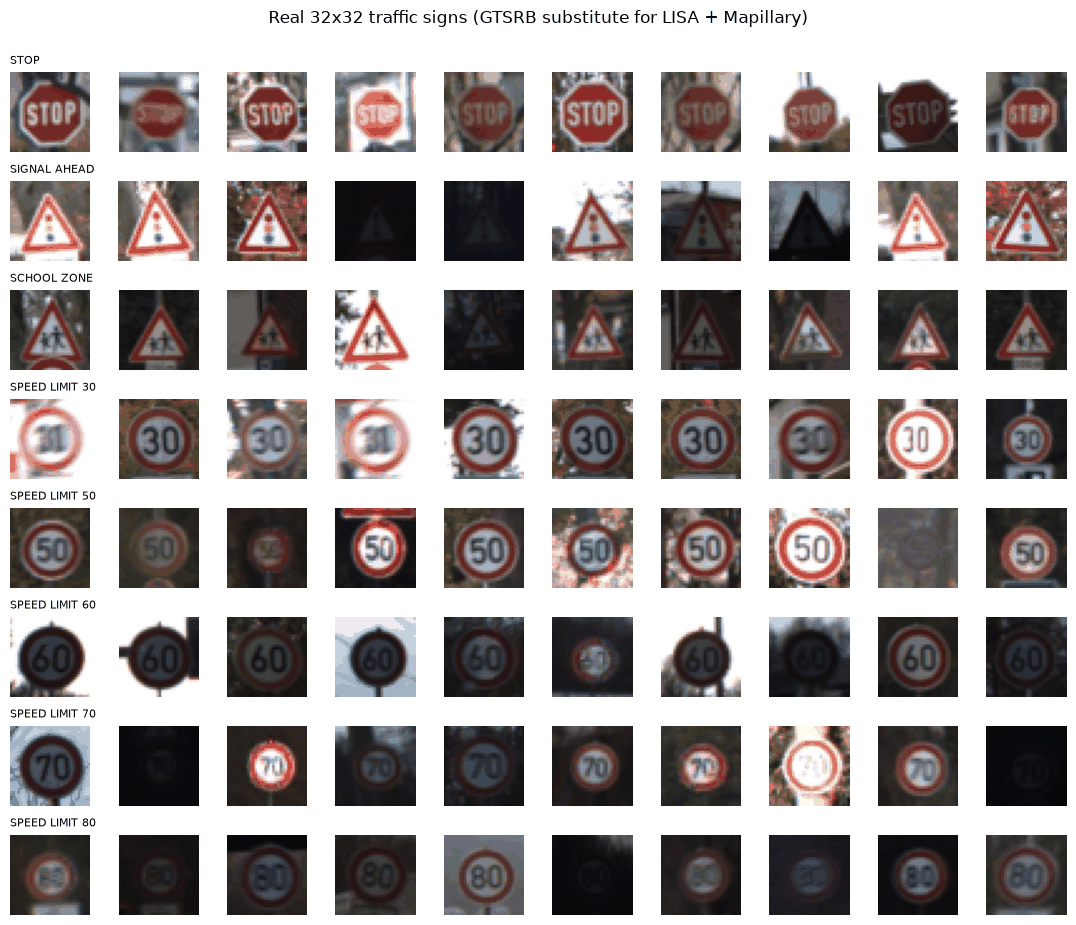

In [5]:

fig, axes = plt.subplots(len(TYPES), 10, figsize=(11, 1.15 * len(TYPES)))
axes = np.atleast_2d(axes)
for r, name in enumerate(TYPES):
    for c in range(10):
        axes[r, c].imshow(POOL[name]["img"][c]); axes[r, c].axis("off")
    axes[r, 0].set_title(name, fontsize=8, loc="left")
plt.suptitle("Real 32x32 traffic signs (GTSRB substitute for LISA + Mapillary)", y=1.0); plt.tight_layout(); plt.show()


## Dataset Exploration and Visualisation

Before any modelling: what the data look like. The cell prints the shape, the feature layout and the original labels with their counts, plots the class distribution, and projects the real images to two dimensions (PCA fitted on the training tracks only), coloured by the ground-truth sign type. Real-versus-fake labels only exist after the attack in section 5, where the same projection is repeated for the detection sets.

Source           : tanganke/gtsrb (train, 26,640 images)
Whole dataset    : 26640 images, 43 original GTSRB classes, 888 tracks (physical signs)
One observation  : a 32 x 32 x 3 RGB image = 3072 features (pixel intensities in [0, 1], ordered R, G, B, row, column)
Feature names    : ['R[0,0]', 'R[0,1]', 'R[0,2]'] ... ['B[31,30]', 'B[31,31]'] (3072 in total)
Targets          : original labels = GTSRB class ids; detector label = real (0) / GAN fake (1), created in section 5


,GTSRB class id,original label,images in GTSRB-train,tracks,pool images used,pool train/val/test
STOP,14,stop,540,18,400,"(226, 87, 87)"
SIGNAL AHEAD,26,traffic signals,420,14,400,"(226, 85, 89)"
SCHOOL ZONE,28,children crossing,360,12,360,"(240, 60, 60)"
SPEED LIMIT 30,1,speed limit 30 km/h,1500,50,400,"(251, 73, 76)"
SPEED LIMIT 50,2,speed limit 50 km/h,1500,50,400,"(239, 73, 88)"
SPEED LIMIT 60,3,speed limit 60 km/h,960,32,400,"(245, 82, 73)"
SPEED LIMIT 70,4,speed limit 70 km/h,1320,44,400,"(243, 78, 79)"
SPEED LIMIT 80,5,speed limit 80 km/h,1260,42,400,"(250, 86, 64)"


Not used here: the other 35 GTSRB classes (e.g. PED XING has only 6 physical signs).


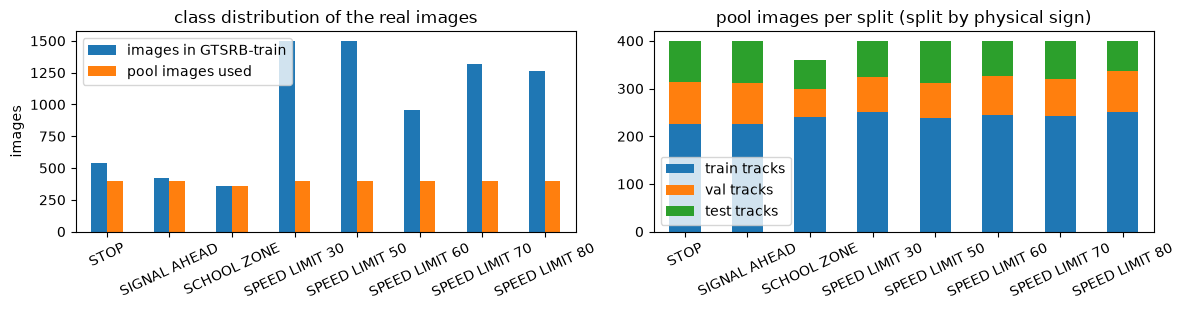

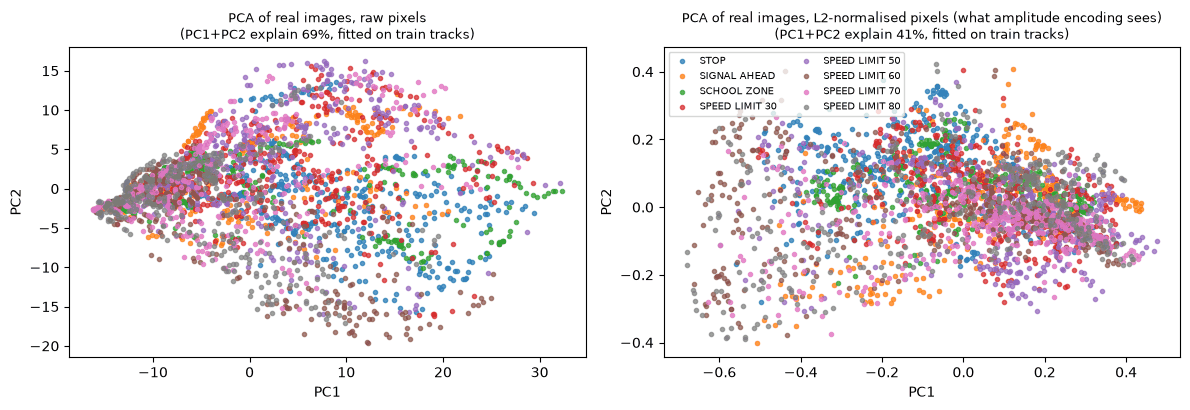

Angle encoding is NOT used in this paper: pixels are amplitude-encoded, so there are no [0, pi] angles to plot; the right-hand panel shows the normalised vectors that become the quantum state.


In [6]:

GTSRB_NAME = {14: "stop", 26: "traffic signals", 28: "children crossing", 1: "speed limit 30 km/h",
              2: "speed limit 50 km/h", 3: "speed limit 60 km/h", 4: "speed limit 70 km/h", 5: "speed limit 80 km/h"}
print("Source           :", SRC)
print("Whole dataset    :", len(labels), "images,", len(np.unique(labels)), "original GTSRB classes,", len(np.unique(track)), "tracks (physical signs)")
print("One observation  : a 32 x 32 x 3 RGB image = 3072 features (pixel intensities in [0, 1], ordered R, G, B, row, column)")
fnames = [f"{ch}[{r},{c}]" for ch in "RGB" for r in range(32) for c in range(32)]
print("Feature names    :", fnames[:3], "...", fnames[-2:], f"({len(fnames)} in total)")
print("Targets          : original labels = GTSRB class ids; detector label = real (0) / GAN fake (1), created in section 5")
rows = {}
for name in TYPES:
    cid = ALL_TYPES[name]
    rows[name] = {"GTSRB class id": cid, "original label": GTSRB_NAME[cid], "images in GTSRB-train": int((labels == cid).sum()),
                  "tracks": POOL[name]["n_tracks"], "pool images used": len(POOL[name]["img"]),
                  "pool train/val/test": tuple(int((POOL[name]["part"] == p).sum()) for p in range(3))}
CNT = pd.DataFrame(rows).T
display(CNT)
print("Not used here: the other", len(np.unique(labels)) - len(TYPES), "GTSRB classes (e.g. PED XING has only 6 physical signs).")

# ---- class distribution ----
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
CNT[["images in GTSRB-train", "pool images used"]].astype(int).plot.bar(ax=ax[0], rot=25)
ax[0].set_title("class distribution of the real images"); ax[0].set_ylabel("images")
sp = np.array([[int((POOL[n]["part"] == p).sum()) for p in range(3)] for n in TYPES])
pd.DataFrame(sp, index=TYPES, columns=["train tracks", "val tracks", "test tracks"]).plot.bar(stacked=True, ax=ax[1], rot=25)
ax[1].set_title("pool images per split (split by physical sign)")
plt.tight_layout(); plt.show()

# ---- 2-D view of the real observations: PCA fitted on the TRAIN tracks only ----
from sklearn.decomposition import PCA
Xr = np.concatenate([POOL[n]["img"].reshape(len(POOL[n]["img"]), -1) for n in TYPES]).astype(np.float32) / 255
yr = np.concatenate([[i] * len(POOL[n]["img"]) for i, n in enumerate(TYPES)])
pr = np.concatenate([POOL[n]["part"] for n in TYPES])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (title, Z) in zip(ax, (("raw pixels", Xr), ("L2-normalised pixels (what amplitude encoding sees)", Xr / np.linalg.norm(Xr, axis=1, keepdims=True)))):
    pca = PCA(n_components=2, random_state=SEED).fit(Z[pr == 0]); P = pca.transform(Z)
    for i, n in enumerate(TYPES):
        a.scatter(P[yr == i, 0], P[yr == i, 1], s=9, alpha=0.7, label=n, color=plt.cm.tab10(i))
    a.set_title(f"PCA of real images, {title}\n(PC1+PC2 explain {pca.explained_variance_ratio_.sum():.0%}, fitted on train tracks)", fontsize=9)
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
ax[1].legend(fontsize=7, ncol=2, loc="best")
plt.tight_layout(); plt.show()
print("Angle encoding is NOT used in this paper: pixels are amplitude-encoded, so there are no [0, pi] angles to plot; the right-hand panel shows the normalised vectors that become the quantum state.")


## 2. The attacker's GAN (WGAN-GP)

Architecture from Figs. 2 and 3: a DCGAN generator (latent 128 -> 512x4x4 -> 256x8x8 -> 128x16x16 -> 3x32x32, Tanh) and a WGAN critic. The training objective is the Wasserstein loss with gradient penalty (lambda = 10) on points interpolated between real and generated images (paper Eq. 2-3; the log terms printed in Eq. 2 of the paper belong to the original GAN and are replaced by the plain critic scores of WGAN-GP). The GAN sees only train and validation tracks, never the test tracks. Note that this GAN is trained for a very small number of iterations, so its images are blurry; the detectors do the real-vs-fake job on exactly these.

In [7]:

class Generator(nn.Module):   # paper Fig. 2 (DCGAN): z(128) -> 512x4x4 -> 256x8x8 -> 128x16x16 -> 3x32x32
    def __init__(self, nz=LATENT, w=GAN_WIDTH):
        super().__init__()
        a, b, c = int(512 * w), int(256 * w), int(128 * w)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, a, 4, 1, 0, bias=False), nn.BatchNorm2d(a), nn.ReLU(True),
            nn.ConvTranspose2d(a, b, 4, 2, 1, bias=False), nn.BatchNorm2d(b), nn.ReLU(True),
            nn.ConvTranspose2d(b, c, 4, 2, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU(True),
            nn.ConvTranspose2d(c, 3, 4, 2, 1), nn.Tanh())
    def forward(self, z):
        return self.net(z.view(z.shape[0], -1, 1, 1))

class Critic(nn.Module):      # paper Fig. 3 (WGAN): 3x32x32 -> 32x16x16 -> 64x8x8 -> 128x4x4 -> 256x1x1 -> 1
    def __init__(self, w=GAN_WIDTH):
        super().__init__()
        a, b, c, d_ = int(32 * w), int(64 * w), int(128 * w), int(256 * w)
        self.net = nn.Sequential(
            nn.Conv2d(3, a, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(a, b, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(b, c, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(c, d_, 4, 1, 0), nn.LeakyReLU(0.2, True),
            nn.Flatten(), nn.Linear(d_, 1))
    def forward(self, x):
        return self.net(x).squeeze(1)

# GAN training set = real images of the train and validation *tracks* (test tracks are never seen by any model)
X_gan = np.concatenate([POOL[n]["img"][POOL[n]["part"] < 2] for n in TYPES])
X_gan = torch.from_numpy(X_gan).permute(0, 3, 1, 2).float() / 127.5 - 1
print("GAN training images:", tuple(X_gan.shape), "| generator params:", sum(p.numel() for p in Generator().parameters()),
      "| critic params:", sum(p.numel() for p in Critic().parameters()))


GAN training images: (2544, 3, 32, 32) | generator params: 1183619 | critic params: 173169


In [8]:

def train_wgan_gp(X, iters, seed):
    torch.manual_seed(seed)
    g, d = Generator(), Critic()
    og = torch.optim.Adam(g.parameters(), LR_GAN, betas=(0.5, 0.9))
    od = torch.optim.Adam(d.parameters(), LR_GAN, betas=(0.5, 0.9))
    hist = []
    for it in range(iters):
        for _ in range(N_CRITIC):
            xr = X[torch.randint(0, len(X), (GAN_BATCH,))]
            with torch.no_grad():
                xf = g(torch.randn(GAN_BATCH, LATENT))
            t = torch.rand(GAN_BATCH, 1, 1, 1)
            xh = (t * xf + (1 - t) * xr).requires_grad_(True)            # Eq. 3: interpolate real/fake
            grad = torch.autograd.grad(d(xh).sum(), xh, create_graph=True)[0]
            gp = ((grad.flatten(1).norm(dim=1) - 1) ** 2).mean()            # gradient penalty, lambda = 10
            ld = d(xf).mean() - d(xr).mean() + LAMBDA_GP * gp                # Wasserstein critic loss
            od.zero_grad(); ld.backward(); od.step()
        lg = -d(g(torch.randn(GAN_BATCH, LATENT))).mean()
        og.zero_grad(); lg.backward(); og.step()
        hist.append((ld.item(), lg.item()))
        if it % max(1, iters // 5) == 0:
            print(f"  iter {it:5d}  critic {ld.item():8.3f}  generator {lg.item():8.3f}  ({time.time()-t0:.0f}s)")
    return g.eval(), np.array(hist)

GAN_SIG = f"{SEED}_{GAN_WIDTH}_{'-'.join(str(ALL_TYPES[t]) for t in TYPES)}_{POOL_PER_TYPE}_{GAN_ITERS}_{len(X_gan)}"
GAN_FILE = os.path.join(DATA_DIR, f"wgangp_{GAN_SIG}.pt")
t0 = time.time()
if os.path.exists(GAN_FILE):                      # cached generator from an earlier run with the same configuration
    G = Generator(); G.load_state_dict(torch.load(GAN_FILE)); G.eval(); gan_hist = None
    print("loaded cached generator", GAN_FILE)
else:
    G, gan_hist = train_wgan_gp(X_gan, GAN_ITERS, SEED)
    torch.save(G.state_dict(), GAN_FILE)
for p_ in G.parameters():
    p_.requires_grad_(False)
print(f"WGAN-GP ready ({time.time()-t0:.0f} s)")


loaded cached generator qc235_data\wgangp_42_0.5_14-26-28-1-2-3-4-5_400_1000_2544.pt
WGAN-GP ready (0 s)


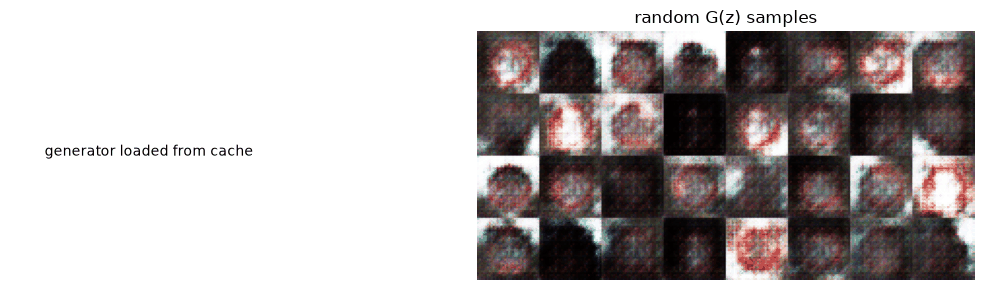

In [9]:

fig = plt.figure(figsize=(11, 3))
ax = fig.add_subplot(1, 3, 1)
if gan_hist is not None:
    k = max(1, len(gan_hist) // 50)
    ax.plot(np.convolve(gan_hist[:, 0], np.ones(k) / k, "valid"), label="critic loss")
    ax.plot(np.convolve(gan_hist[:, 1], np.ones(k) / k, "valid"), label="generator loss")
    ax.legend(); ax.set_title("WGAN-GP training"); ax.set_xlabel("generator iteration")
else:
    ax.text(0.1, 0.5, "generator loaded from cache"); ax.axis("off")
with torch.no_grad():
    s = G(torch.randn(32, LATENT, generator=torch.Generator().manual_seed(SEED)))
grid = ((s.permute(0, 2, 3, 1) + 1) / 2).clamp(0, 1).numpy()
ax2 = fig.add_subplot(1, 3, (2, 3)); ax2.axis("off"); ax2.set_title("random G(z) samples")
ax2.imshow(np.concatenate([np.concatenate(list(grid[r * 8:(r + 1) * 8]), axis=1) for r in range(4)], axis=0))
plt.tight_layout(); plt.show()


## 3. The ResNet9 sign-type classifier (Fig. 4 and 5)

In the defence pipeline the first network reads the sign type, and the matching type-specific detector then decides real or fake. We train it on real training-track images and measure the accuracy on real held-out tracks. (The paper reports 0.97 on real and fake images together; the fakes' true type is only known to a human, so our number is not exactly the same quantity.)

In [10]:

def conv_bn(ci, co, pool=False):
    L = [nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True)]
    return nn.Sequential(*(L + ([nn.MaxPool2d(2)] if pool else [])))

class Residual(nn.Module):
    def __init__(self, c):
        super().__init__(); self.f = nn.Sequential(conv_bn(c, c), conv_bn(c, c))
    def forward(self, x):
        return x + self.f(x)

class ResNet9(nn.Module):     # paper Fig. 5: ResNet9 traffic-sign TYPE classifier (width scaled by R9_WIDTH, CHOICE)
    def __init__(self, n_classes, w=R9_WIDTH):
        super().__init__()
        c = [int(v * w) for v in (64, 128, 256, 512)]
        self.net = nn.Sequential(conv_bn(3, c[0]), conv_bn(c[0], c[1], True), Residual(c[1]),
                                 conv_bn(c[1], c[2], True), conv_bn(c[2], c[3], True), Residual(c[3]),
                                 nn.MaxPool2d(4), nn.Flatten(), nn.Dropout(0.2), nn.Linear(c[3], n_classes))
    def forward(self, x):
        return self.net(x)

def to_t(u8):   # uint8 [n,32,32,3] -> float [n,3,32,32] in [0,1]
    return torch.from_numpy(u8).permute(0, 3, 1, 2).float() / 255

type_id = {n: i for i, n in enumerate(TYPES)}
def part_xy(p):
    X = np.concatenate([POOL[n]["img"][POOL[n]["part"] == p] for n in TYPES])
    y = np.concatenate([np.full(int((POOL[n]["part"] == p).sum()), type_id[n]) for n in TYPES])
    return to_t(X), torch.from_numpy(y)

def predict(model, X, bs=256):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(F.softmax(model(X[i:i + bs]), 1))
    return torch.cat(out)

torch.manual_seed(SEED)
(Xtr, ytr), (Xva, yva), (Xte, yte) = part_xy(0), part_xy(1), part_xy(2)
R9 = ResNet9(len(TYPES)); opt = torch.optim.Adam(R9.parameters(), 2e-3)
t0 = time.time(); best = (-1, None)
for ep in range(R9_EPOCHS):
    R9.train(); perm = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), 32):
        b = perm[i:i + 32]
        # light augmentation (CHOICE): random shift by up to 2 px
        xb = torch.roll(Xtr[b], shifts=(int(torch.randint(-2, 3, (1,))), int(torch.randint(-2, 3, (1,)))), dims=(2, 3))
        loss = F.cross_entropy(R9(xb), ytr[b]); opt.zero_grad(); loss.backward(); opt.step()
    va = (predict(R9, Xva).argmax(1) == yva).float().mean().item()
    if va >= best[0]: best = (va, copy.deepcopy(R9.state_dict()))
    print(f"epoch {ep+1}/{R9_EPOCHS}  val acc {va:.3f}  ({time.time()-t0:.0f}s)")
R9.load_state_dict(best[1]); R9.eval()
R9_TEST_ACC = (predict(R9, Xte).argmax(1) == yte).float().mean().item()
print(f"ResNet9 sign-type classifier: test accuracy on real held-out tracks = {R9_TEST_ACC:.3f} "
      f"({len(Xte)} images, {len(TYPES)} types) | trainable params: {sum(p.numel() for p in R9.parameters()):,}")


epoch 1/12  val acc 0.393  (80s)


epoch 2/12  val acc 0.394  (122s)


epoch 3/12  val acc 0.513  (155s)


epoch 4/12  val acc 0.715  (189s)


epoch 5/12  val acc 0.869  (220s)


...

epoch 9/12  val acc 0.942  (329s)


epoch 10/12  val acc 0.939  (355s)


epoch 11/12  val acc 0.947  (376s)


epoch 12/12  val acc 0.913  (399s)


ResNet9 sign-type classifier: test accuracy on real held-out tracks = 0.969 (616 images, 8 types) | trainable params: 1,645,608


## 4. The deepfake attack (Eq. 1)

For each real input image *x* the attacker looks for the latent vector *z\** that makes G(z) as far as possible from *x* (squared L2 distance), starting from a fixed number of random *z* and keeping the best one. We compare with a naive attacker that just draws one random *z* and measure the **attack success**: how often the sign classifier then reads a *different* sign than the one the camera saw.

In [11]:

def deepfake_attack(x, n_init, steps, lr, seed):
    """Eq. 1: z* = argmax_z ||G(z) - x||^2 by gradient ascent from n_init random z; returns the fake image G(z*) in [-1,1]."""
    gen = torch.Generator().manual_seed(seed)
    best_img = torch.zeros_like(x); best_d = torch.full((len(x),), -1.0)
    for r in range(n_init):
        z = torch.randn(len(x), LATENT, generator=gen).requires_grad_(True)
        opt = torch.optim.Adam([z], lr)
        for _ in range(steps):
            loss = -((G(z) - x) ** 2).flatten(1).sum()
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                z.mul_(math.sqrt(LATENT) / z.norm(dim=1, keepdim=True))   # CHOICE: keep z on the sphere of typical N(0,I) vectors
        with torch.no_grad():
            img = G(z); dist = ((img - x) ** 2).flatten(1).sum(1)
            better = dist > best_d
            best_img[better] = img[better]; best_d[better] = dist[better]
    return best_img

# attacker inputs: real images (any track) of every type
ax_u8, ax_src = [], []
for name in TYPES:
    sel = rng.choice(len(POOL[name]["img"]), size=min(ATTACK_INPUTS, len(POOL[name]["img"])), replace=False)
    ax_u8.append(POOL[name]["img"][sel]); ax_src += [type_id[name]] * len(sel)
ax_u8 = np.concatenate(ax_u8); ax_src = torch.tensor(ax_src)
x_in = to_t(ax_u8) * 2 - 1

t0 = time.time()
fakes, fakes_rand = [], []
for i in range(0, len(x_in), 128):
    fakes.append(deepfake_attack(x_in[i:i + 128], N_INIT, ATTACK_STEPS, ATTACK_LR, SEED + i))
    fakes_rand.append(deepfake_attack(x_in[i:i + 128], 1, 0, ATTACK_LR, SEED + i))     # baseline: a single random z, no optimisation
fakes = torch.cat(fakes); fakes_rand = torch.cat(fakes_rand)
q8 = lambda f: torch.round(((f + 1) / 2).clamp(0, 1) * 255) / 255                     # save as 8-bit image like a real photo
fakes01, fakes_rand01 = q8(fakes), q8(fakes_rand)
prob = predict(R9, fakes01); conf, pred = prob.max(1)
prob_r = predict(R9, fakes_rand01); pred_r = prob_r.argmax(1)
dist_opt = ((fakes - x_in) ** 2).flatten(1).mean(1); dist_rnd = ((fakes_rand - x_in) ** 2).flatten(1).mean(1)
print(f"attack finished in {time.time()-t0:.0f} s for {len(x_in)} inputs")
print(f"mean squared distance to the input: optimised z* {dist_opt.mean():.3f} vs random z {dist_rnd.mean():.3f}")
print(f"attack success (ResNet9 reads a DIFFERENT sign type): optimised {(pred != ax_src).float().mean():.1%} | random z {(pred_r != ax_src).float().mean():.1%}")
print("ResNet9 confidence on the optimised fakes: mean %.2f, share >0.9: %.1f%%" % (conf.mean(), 100 * (conf > 0.9).float().mean()))
print("how the fakes are read:", {TYPES[k]: int(((pred == k) & (ax_src != k)).sum()) for k in range(len(TYPES))})


attack finished in 145 s for 3160 inputs
mean squared distance to the input: optimised z* 1.353 vs random z 0.602
attack success (ResNet9 reads a DIFFERENT sign type): optimised 89.6% | random z 87.8%
ResNet9 confidence on the optimised fakes: mean 0.71, share >0.9: 24.7%
how the fakes are read: {'STOP': 216, 'SIGNAL AHEAD': 0, 'SCHOOL ZONE': 13, 'SPEED LIMIT 30': 301, 'SPEED LIMIT 50': 623, 'SPEED LIMIT 60': 937, 'SPEED LIMIT 70': 194, 'SPEED LIMIT 80': 548}


## 5. The real / fake detection dataset

For every sign type *t* the paper trains a detector on real images of type *t* and on fake images that the classifier reads as type *t*. We reproduce this: fakes are ranked by ResNet9 confidence (replacing the manual removal of unrecognisable fakes), real and fake classes are balanced by undersampling, and everything is split 60 / 20 / 20 (real images by physical sign).

               images (real+fake) train/val/test  \
STOP                          160   (96, 32, 32)   
SIGNAL AHEAD                  160   (96, 32, 32)   
SCHOOL ZONE                   160   (96, 32, 32)   
SPEED LIMIT 30                160   (96, 32, 32)   
SPEED LIMIT 50                160   (96, 32, 32)   
SPEED LIMIT 60                160   (96, 32, 32)   
SPEED LIMIT 70                160   (96, 32, 32)   
SPEED LIMIT 80                160   (96, 32, 32)   

               fakes ResNet9 reads as this type (argmax)  \
STOP                                                 216   
SIGNAL AHEAD                                           0   
SCHOOL ZONE                                           13   
SPEED LIMIT 30                                       301   
SPEED LIMIT 50                                       623   
SPEED LIMIT 60                                       937   
SPEED LIMIT 70                                       194   
SPEED LIMIT 80                                     

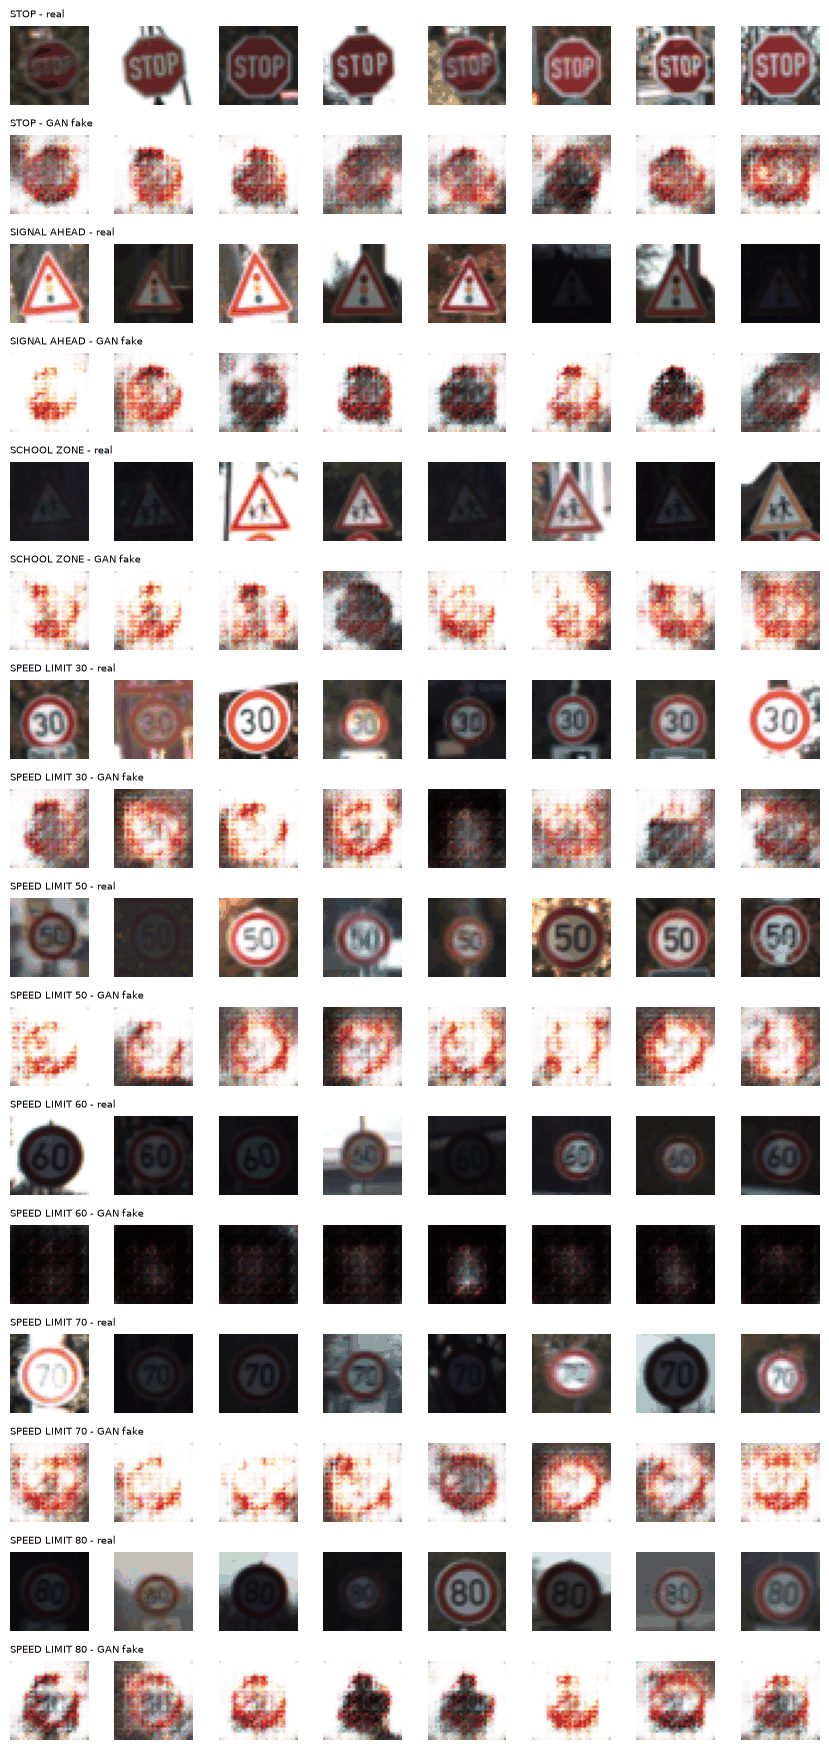

In [12]:

def build_sets(name, seed):
    """Balanced real/fake dataset of one sign type, 60/20/20 split (real by track; fakes: highest-confidence reading as this type)."""
    r = np.random.default_rng(1000 * seed + type_id[name])
    k = type_id[name]
    cand = torch.nonzero(ax_src != k).flatten()                     # fakes made from a sign of another type ...
    cand = cand[torch.argsort(-prob[cand, k])]                      # ... ranked by how clearly ResNet9 reads them as type k (replaces manual clean-up)
    pool = POOL[name]
    n_half = min(N_PER_TYPE // 2, len(cand), len(pool["img"]))
    tgt = [int(round(SPLIT[0] * n_half)), int(round(SPLIT[1] * n_half))]; tgt.append(n_half - sum(tgt))
    real_idx = []
    for p in range(3):
        avail = np.flatnonzero(pool["part"] == p)
        real_idx.append(r.choice(avail, size=min(tgt[p], len(avail)), replace=False))
    n_half = min(n_half, sum(len(a) for a in real_idx)); n_per = [len(a) for a in real_idx]
    fk = cand[:sum(n_per)].numpy(); r.shuffle(fk); cuts = np.cumsum([0] + n_per)
    out = {}
    for p, sp in enumerate(("train", "val", "test")):
        xr = to_t(pool["img"][real_idx[p]]); xf = fakes01[fk[cuts[p]:cuts[p + 1]]]
        X = torch.cat([xr, xf]); y = torch.cat([torch.zeros(len(xr)), torch.ones(len(xf))])
        out[sp] = (X, y)
    out["fake_conf"] = float(prob[cand[:sum(n_per)], k].mean())
    return out

SETS = {name: build_sets(name, 0) for name in TYPES}
print(pd.DataFrame({n: {"images (real+fake)": sum(len(v[1]) for k, v in s.items() if k != "fake_conf"),
                        "train/val/test": tuple(len(s[k][1]) for k in ("train", "val", "test")),
                        "fakes ResNet9 reads as this type (argmax)": int(((pred == type_id[n]) & (ax_src != type_id[n])).sum()),
                        "mean P(type) of the fakes used": round(s["fake_conf"], 2)} for n, s in SETS.items()}).T)

fig, axes = plt.subplots(2 * len(TYPES), 8, figsize=(8.5, 1.1 * 2 * len(TYPES)))
axes = np.atleast_2d(axes)
for r_, name in enumerate(TYPES):
    X, y = SETS[name]["train"]
    for row, lab in ((0, 0), (1, 1)):
        ids = torch.nonzero(y == lab).flatten()[:8]
        for c in range(8):
            ax = axes[2 * r_ + row, c]; ax.axis("off")
            if c < len(ids): ax.imshow(X[ids[c]].permute(1, 2, 0).numpy())
        axes[2 * r_ + row, 0].set_title(f"{name} - {'real' if lab == 0 else 'GAN fake'}", fontsize=7, loc="left")
plt.tight_layout(); plt.show()      # analogue of the paper's Fig. 8


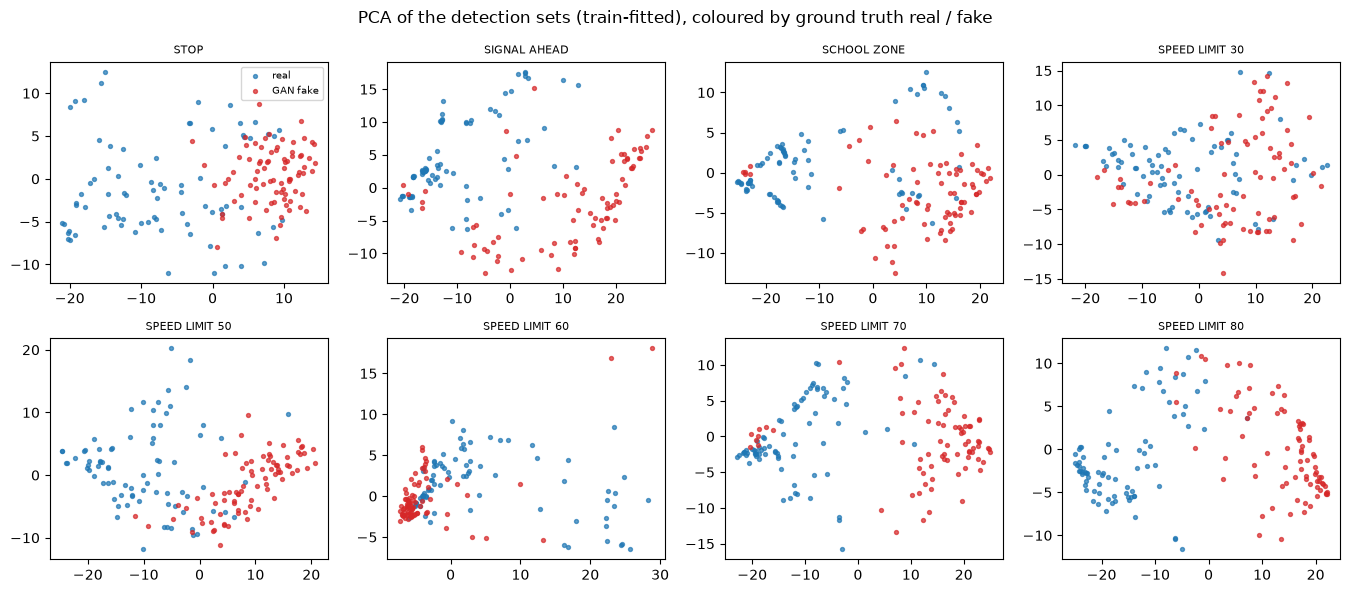

In [13]:

# 2-D view of the detection sets: PCA (fitted on the training part) of real vs GAN-fake images per sign type
from sklearn.decomposition import PCA
cols = min(4, len(TYPES)); rows_ = int(np.ceil(len(TYPES) / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(3.4 * cols, 3 * rows_), squeeze=False)
for ax_, name in zip(axes.ravel(), TYPES):
    Xt, yt = SETS[name]["train"]; Xs = torch.cat([SETS[name][k][0] for k in ("train", "val", "test")]).flatten(1).numpy()
    ys = torch.cat([SETS[name][k][1] for k in ("train", "val", "test")]).numpy()
    P = PCA(2, random_state=SEED).fit(Xt.flatten(1).numpy()).transform(Xs)
    for lab, c, nm in ((0, "tab:blue", "real"), (1, "tab:red", "GAN fake")):
        ax_.scatter(P[ys == lab, 0], P[ys == lab, 1], s=8, alpha=0.7, c=c, label=nm)
    ax_.set_title(name, fontsize=8)
axes.ravel()[0].legend(fontsize=7)
for ax_ in axes.ravel()[len(TYPES):]: ax_.axis("off")
plt.suptitle("PCA of the detection sets (train-fitted), coloured by ground truth real / fake"); plt.tight_layout(); plt.show()


## 6. Quantum Circuit Architecture: the quantum neural network of the paper in PennyLane

Each quantum NN (Fig. 7b-d):

1. **Amplitude encoding** (Eq. 4): the 3 x 32 x 32 = 3072 pixel intensities form the amplitudes of a 12-qubit state (4096 amplitudes, zero padded, normalised to unit length).
2. A **rotation layer** Ry(theta) and Rz(theta) on every qubit followed by a CNOT chain.
3. Three **quantum convolution** layers U(phi) and three **quantum pooling** layers P(phi), alternating, each a two-qubit gate built from three CNOTs and rotations (Fig. 7c, 7d). Within a layer all gates share the same three angles.
4. The output is the expectation value <Z> of the last qubit, a number between -1 and 1.

32 such circuits with independent parameters give the 32 neurons of the first hidden layer. Below we write one circuit with PennyLane, show a 6-qubit miniature (the size drawn in the paper's figure), and confirm that the parameter count is 42 per circuit.

In [14]:

# ---------- The quantum NN of the paper (Fig. 7b-d) written in PennyLane ----------
def U_gate(phi, a, b):            # Fig. 7(c) two-qubit convolution gate U(phi)
    qml.RZ(-math.pi / 2, wires=b); qml.CNOT(wires=[b, a])
    qml.RZ(phi[0], wires=a); qml.RY(phi[1], wires=b)
    qml.CNOT(wires=[a, b]); qml.RY(phi[2], wires=b)
    qml.CNOT(wires=[b, a]); qml.RZ(math.pi / 2, wires=a)

def P_gate(phi, a, b):            # Fig. 7(d) two-qubit pooling gate P(phi)
    qml.RZ(-math.pi / 2, wires=b); qml.CNOT(wires=[b, a])
    qml.RZ(phi[0], wires=a); qml.RY(phi[1], wires=b)
    qml.CNOT(wires=[a, b]); qml.RY(phi[2], wires=b)

def brick(gate, phi, nq):         # gate on (0,1),(2,3),... then on (1,2),(3,4),...  (CHOICE: brickwork as drawn in Fig. 7b)
    for a in range(0, nq - 1, 2): gate(phi, a, a + 1)
    for a in range(1, nq - 1, 2): gate(phi, a, a + 1)

def qnn_circuit(x, w, nq=N_QUBITS):
    # amplitude encoding (Eq. 4): 3 x 32 x 32 = 3072 intensities, zero-padded to 2^12 = 4096 amplitudes, normalised to unit norm
    qml.AmplitudeEmbedding(x, wires=range(nq), normalize=True, pad_with=0.0)
    for i in range(nq): qml.RY(w[i], wires=i)                  # rotation layer: Ry(theta_1..nq)
    for i in range(nq): qml.RZ(w[nq + i], wires=i)             #                 Rz(theta_nq+1..2nq)
    for i in range(nq - 1): qml.CNOT(wires=[i, i + 1])        # CNOT chain of Fig. 7(b)
    for l in range(3):                                         # 3 quantum-convolution + 3 quantum-pooling layers, parameters shared inside a layer
        brick(U_gate, w[2 * nq + 6 * l: 2 * nq + 6 * l + 3], nq)
        brick(P_gate, w[2 * nq + 6 * l + 3: 2 * nq + 6 * l + 6], nq)
    return qml.expval(qml.PauliZ(nq - 1))                     # <Z> on the last qubit

N_QPARAMS = 2 * N_QUBITS + 18
print("trainable parameters per quantum circuit:", N_QPARAMS, "(= 2*12 rotation + 3 conv layers*3 + 3 pool layers*3)")

# miniature 6-qubit version, same drawing as Fig. 7(b)
dev6 = qml.device("default.qubit", wires=6)
demo = qml.QNode(lambda w: qnn_circuit(np.ones(64), w, nq=6), dev6)
from collections import Counter
tape6 = qml.workflow.construct_tape(demo)(np.zeros(2 * 6 + 18))
print("6-qubit miniature, gate counts:", dict(Counter(op.name for op in tape6.operations)))
print("12-qubit circuit used in the paper: same pattern, %d wires, %d trainable parameters" % (N_QUBITS, N_QPARAMS))


trainable parameters per quantum circuit: 42 (= 2*12 rotation + 3 conv layers*3 + 3 pool layers*3)
6-qubit miniature, gate counts: {'AmplitudeEmbedding': 1, 'RY': 66, 'RZ': 81, 'CNOT': 80}
12-qubit circuit used in the paper: same pattern, 12 wires, 42 trainable parameters


### Drawing of the circuit that is executed

The boxed version below groups every U and P two-qubit gate into one box (a box decomposes into exactly the gates of U_gate / P_gate above); an assertion checks that it returns the same expectation value as the gate-level QNode. The gate-level drawings of the two boxes follow, then qubit count, depth and parameter count.

equivalence of the boxed drawing and the executed gate-level circuit: 0.0007864214 vs 0.0007864214


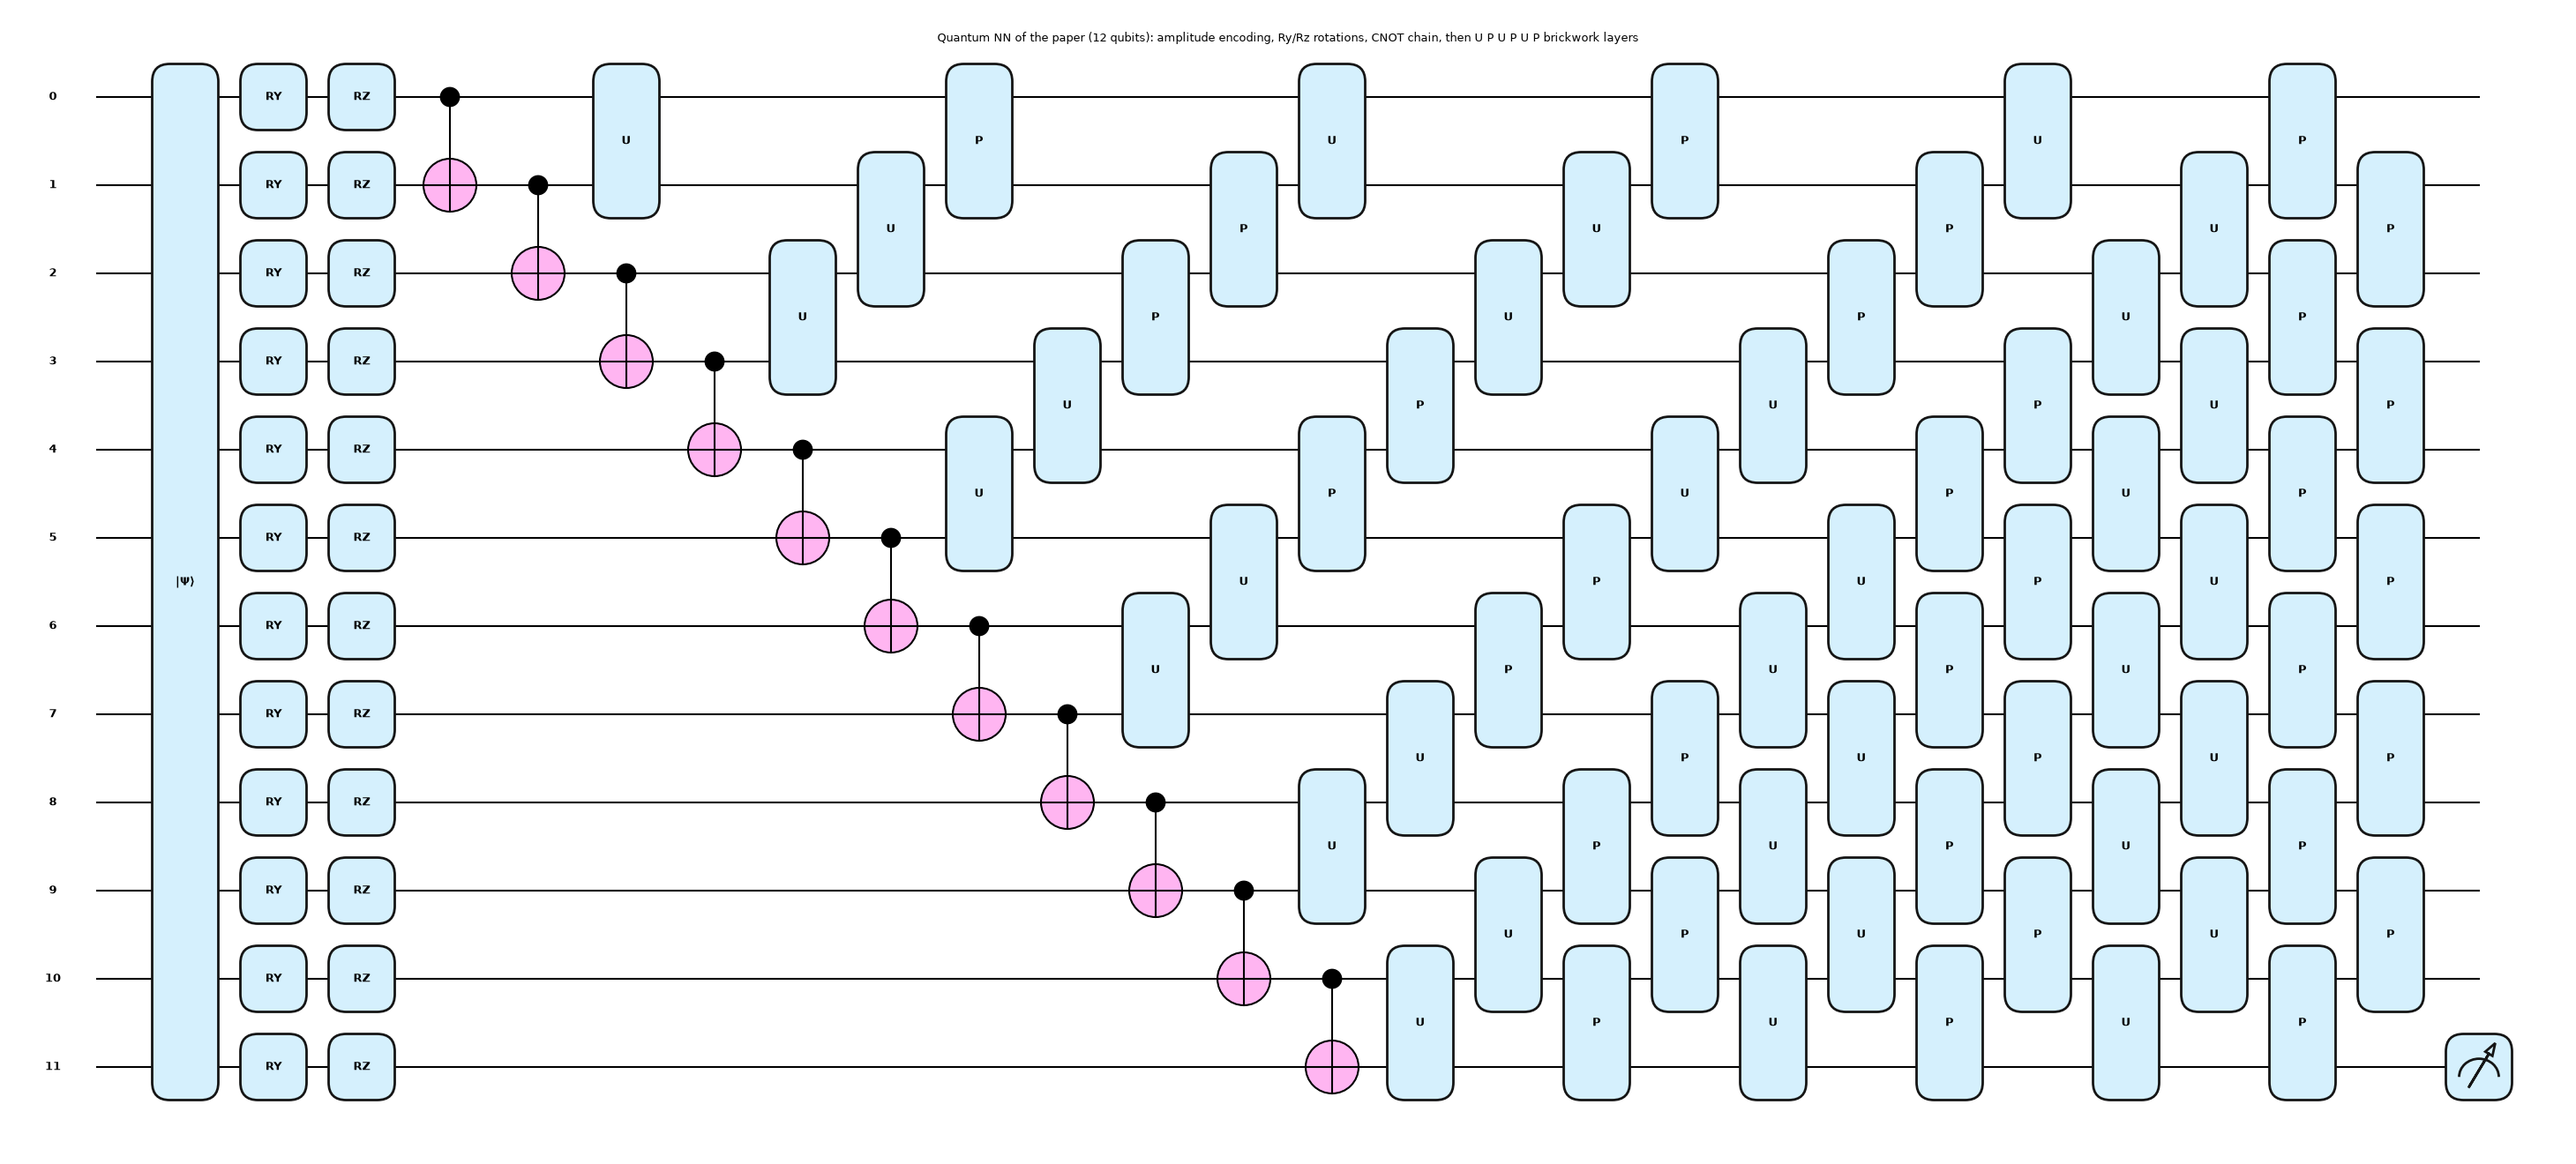

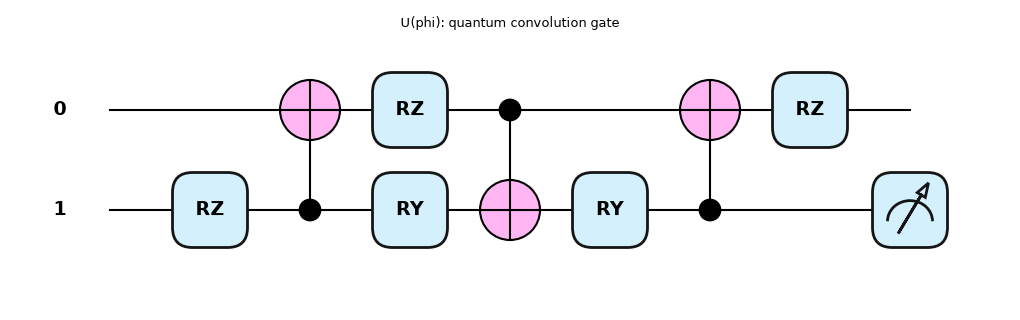

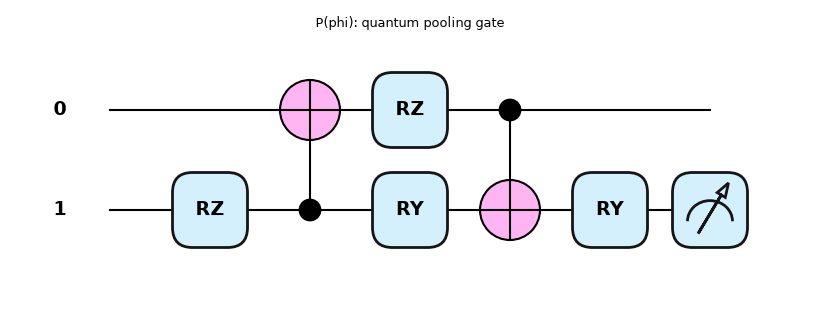

qubits                     : 12 (2^12 = 4096 amplitudes hold the 3072 pixels + 1024 zeros)
circuit depth (gate level) : 81 (incl. the state-preparation layer)
trainable parameters       : 42 per circuit  x 32 circuits = 1344 quantum parameters
gate counts per circuit    : {'AmplitudeEmbedding': 1, 'RY': 144, 'RZ': 177, 'CNOT': 176}
distinct architectures     : 1 (all 32 circuits share it, only the parameters differ)


In [15]:

# ---- the architecture actually executed: the 12-qubit QNode with U / P two-qubit gates grouped into labelled boxes ----
class _Block(qml.operation.Operation):
    '''U(phi) (pool=False) or P(phi) (pool=True) of Fig. 7(c)/(d) as ONE two-qubit box that decomposes into the gates of U_gate / P_gate.'''
    num_wires = 2; num_params = 1; ndim_params = (1,)
    def __init__(self, phi, wires, pool=False):
        super().__init__(phi, wires=wires)
        self.hyperparameters["pool"] = pool
    @staticmethod
    def compute_decomposition(phi, wires, pool=False):
        a, b = wires
        ops = [qml.RZ(-math.pi / 2, wires=b), qml.CNOT(wires=[b, a]), qml.RZ(phi[0], wires=a), qml.RY(phi[1], wires=b),
               qml.CNOT(wires=[a, b]), qml.RY(phi[2], wires=b)]
        if not pool:
            ops += [qml.CNOT(wires=[b, a]), qml.RZ(math.pi / 2, wires=a)]
        return ops
    def label(self, decimals=None, base_label=None, cache=None):
        return "P" if self.hyperparameters["pool"] else "U"

def qnn_circuit_boxes(x, w, nq=N_QUBITS):
    qml.AmplitudeEmbedding(x, wires=range(nq), normalize=True, pad_with=0.0)
    for i in range(nq): qml.RY(w[i], wires=i)
    for i in range(nq): qml.RZ(w[nq + i], wires=i)
    for i in range(nq - 1): qml.CNOT(wires=[i, i + 1])
    for l in range(3):
        for pool in (False, True):
            phi = w[2 * nq + 6 * l + (3 if pool else 0): 2 * nq + 6 * l + (3 if pool else 0) + 3]
            for a in range(0, nq - 1, 2): _Block(phi, wires=[a, a + 1], pool=pool)
            for a in range(1, nq - 1, 2): _Block(phi, wires=[a, a + 1], pool=pool)
    return qml.expval(qml.PauliZ(nq - 1))

dev12 = qml.device("default.qubit", wires=N_QUBITS)
qn_flat = qml.QNode(qnn_circuit, dev12); qn_box = qml.QNode(qnn_circuit_boxes, dev12)
rs = np.random.default_rng(1); x_t = rs.random(3072); w_t = rs.uniform(0, 2 * np.pi, N_QPARAMS)
v_flat, v_box = float(qn_flat(x_t, w_t)), float(qn_box(x_t, w_t))
print(f"equivalence of the boxed drawing and the executed gate-level circuit: {v_flat:.10f} vs {v_box:.10f}")
assert abs(v_flat - v_box) < 1e-9

fig, ax = qml.draw_mpl(qn_box, style="pennylane", decimals=None, show_all_wires=True, fontsize=9)(x_t, w_t)
fig.suptitle("Quantum NN of the paper (12 qubits): amplitude encoding, Ry/Rz rotations, CNOT chain, then U P U P U P brickwork layers", fontsize=9)
plt.show()

# gate-level view of the two building blocks (Fig. 7c, 7d)
dev2 = qml.device("default.qubit", wires=2)
for nm, g in (("U(phi): quantum convolution gate", U_gate), ("P(phi): quantum pooling gate", P_gate)):
    qn2 = qml.QNode(lambda phi, g=g: (g(phi, 0, 1), qml.expval(qml.PauliZ(1)))[1], dev2)
    f2, _ = qml.draw_mpl(qn2, style="pennylane", decimals=None)(np.array([0.1, 0.2, 0.3])); f2.suptitle(nm, fontsize=9); plt.show()

tape = qml.workflow.construct_tape(qn_flat)(x_t, w_t)
from collections import Counter
print("qubits                     :", N_QUBITS, "(2^12 = 4096 amplitudes hold the 3072 pixels + 1024 zeros)")
print("circuit depth (gate level) :", tape.graph.get_depth(), "(incl. the state-preparation layer)")
print("trainable parameters       :", N_QPARAMS, "per circuit  x", N_CIRCUITS, "circuits =", N_QPARAMS * N_CIRCUITS, "quantum parameters")
print("gate counts per circuit    :", dict(Counter(op.name for op in tape.operations)))
print("distinct architectures     : 1 (all 32 circuits share it, only the parameters differ)")


### A fast simulator, verified against PennyLane

Training needs 32 circuits for every image in a batch plus gradients. PennyLane's `default.qubit` evaluates one circuit per call, which would take hours here. We therefore apply exactly the same gates to a `[circuits, batch, 4096]` state tensor in torch (exact state-vector arithmetic, automatic differentiation) and **check it against PennyLane**: same expectation values and same gradients, to float32 precision. The paper used finite differences for the gradient; exact gradients are the better choice on a noiseless simulator.

In [16]:

# ---------- Fast batched simulator of the same circuit in torch (exact state vector, 32 circuits x batch at once) ----------
# Why: PennyLane runs one circuit per call; here 32 circuits x thousands of training images x gradients would take hours.
# We therefore re-implement the identical gate sequence on [circuits, batch, 4096] tensors and CHECK it against PennyLane below.
NQ, DIM = N_QUBITS, 2 ** N_QUBITS

def _cnot_chain_perm():
    inv = np.zeros(DIM, dtype=np.int64)
    for b in range(DIM):
        bits = [(b >> (NQ - 1 - i)) & 1 for i in range(NQ)]
        for i in range(NQ - 1): bits[i + 1] ^= bits[i]
        f = 0
        for i in range(NQ): f = (f << 1) | bits[i]
        inv[f] = b
    return torch.from_numpy(inv)
PERM = _cnot_chain_perm()

def _rz(t):
    e = torch.exp(-0.5j * t.to(torch.complex64)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)
def _ry(t):
    c = torch.cos(t / 2).to(torch.complex64); s = torch.sin(t / 2).to(torch.complex64)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
def _kron(A, B):
    return torch.einsum("...ab,...cd->...acbd", A, B).reshape(*A.shape[:-2], 4, 4)
_I2 = torch.eye(2, dtype=torch.complex64)
_CN_AB = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=torch.complex64)   # control a, target b
_CN_BA = torch.tensor([[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]], dtype=torch.complex64)   # control b, target a

def _gate_matrix(phi, pool):          # phi [K,3] -> 4x4 matrix of U(phi) or P(phi) in basis |a b>
    K = phi.shape[0]; I = _I2.expand(K, 2, 2)
    G_ = _kron(I, _rz(torch.full((K,), -math.pi / 2)))
    G_ = _CN_BA @ G_
    G_ = _kron(_rz(phi[:, 0]), _ry(phi[:, 1])) @ G_
    G_ = _CN_AB @ G_
    G_ = _kron(I, _ry(phi[:, 2])) @ G_
    if not pool:
        G_ = _CN_BA @ G_
        G_ = _kron(_rz(torch.full((K,), math.pi / 2)), I) @ G_
    return G_

def _apply(state, M, q, nbits):       # apply per-circuit matrix M [K,2^nbits,2^nbits] to qubits q..q+nbits-1
    K, B, _ = state.shape
    st = state.reshape(K, B * 2 ** q, 2 ** nbits, 2 ** (NQ - q - nbits))
    return torch.matmul(M.unsqueeze(1), st).reshape(K, B, DIM)

def qnn_forward(x, w):
    """x [B,3072] pixel intensities, w [K,42] -> <Z_12> of every circuit, shape [B,K]."""
    B, K = x.shape[0], w.shape[0]
    xp = torch.zeros(B, DIM); xp[:, :x.shape[1]] = x
    xp = xp / xp.norm(dim=1, keepdim=True)                                   # amplitude encoding
    st = xp.to(torch.complex64).unsqueeze(0).expand(K, B, DIM)
    for i in range(NQ):
        st = _apply(st, _rz(w[:, NQ + i]) @ _ry(w[:, i]), i, 1)
    st = st[..., PERM]                                                       # CNOT chain
    for l in range(3):
        for pool in (False, True):
            off = 2 * NQ + 6 * l + (3 if pool else 0)
            Gm = _gate_matrix(w[:, off:off + 3], pool)
            for q in range(0, NQ - 1, 2): st = _apply(st, Gm, q, 2)
            for q in range(1, NQ - 1, 2): st = _apply(st, Gm, q, 2)
    p = (st.real ** 2 + st.imag ** 2).reshape(K, B, DIM // 2, 2)
    return (p[..., 0] - p[..., 1]).sum(-1).t()                               # <Z> on the last qubit

# ---- check 1: expectation values equal PennyLane's ----
torch.manual_seed(0)
xs = torch.rand(3, 3072); ws = torch.rand(4, N_QPARAMS) * 2 * math.pi
qn_ref = qml.QNode(qnn_circuit, qml.device("default.qubit", wires=NQ))
ref = np.array([[float(qn_ref(xs[b].double().numpy(), ws[k].double().numpy())) for k in range(4)] for b in range(3)])
mine = qnn_forward(xs, ws).numpy()
print("max |PennyLane - fast simulator| of <Z> :", np.abs(ref - mine).max())
assert np.allclose(ref, mine, atol=1e-5)

# ---- check 2: gradients w.r.t. the circuit parameters equal PennyLane's (backprop through default.qubit) ----
qn_bp = qml.QNode(qnn_circuit, qml.device("default.qubit", wires=NQ), interface="torch", diff_method="backprop")
w0 = ws[0].double().clone().requires_grad_(True); qn_bp(xs[0].double(), w0).backward()
w1 = ws[:1].clone().requires_grad_(True); qnn_forward(xs[:1], w1)[0, 0].backward()
print("max |gradient difference| :", (w0.grad.float() - w1.grad[0]).abs().max().item())
assert torch.allclose(w0.grad.float(), w1.grad[0], atol=1e-4)


max |PennyLane - fast simulator| of <Z> : 7.003889410106545e-07


max |gradient difference| : 5.364418029785156e-07


## 7. The hybrid network, the classical baselines, and Table 2

*Hybrid*: 32 quantum neurons -> Tanh -> 120 neurons -> Tanh -> 1 output (probability that the image is fake). *Classical CNN-k*: k blocks of Conv3x3(pad 1) - BatchNorm - ReLU - MaxPool, dropout 20 %, one fully connected layer with 2 outputs. The paper does not print the channel counts, but its Table 2 does print the total parameters; channel widths 32, 64, 128, 256, 512 reproduce all five numbers exactly, which is a strong check that the baselines match. The table below also recomputes the memory column with Eq. 6.

In [17]:

class HybridQNN(nn.Module):
    """Paper Fig. 7(a): 32 quantum NNs -> 32 neurons, Tanh, fully connected 120 neurons, Tanh, 1 output neuron (fake probability)."""
    def __init__(self, k=N_CIRCUITS):
        super().__init__()
        self.qw = nn.Parameter(torch.randn(k, N_QPARAMS) * Q_INIT_STD)         # CHOICE: Gaussian init, std 0.5
        self.fc1 = nn.Linear(k, 120); self.fc2 = nn.Linear(120, 1)
    def forward(self, x):
        q = qnn_forward(x.flatten(1), self.qw)                                  # [B,32] quantum features in [-1,1]
        return self.fc2(torch.tanh(self.fc1(torch.tanh(q)))).squeeze(1)         # CHOICE: Tanh also after the 120-neuron layer

class ClassicalCNN(nn.Module):
    """Paper Fig. 6: k x [Conv3x3(pad 1) - BatchNorm - ReLU - MaxPool], dropout 20 %, one fully connected layer, 2 outputs.
    Channel widths 32, 64, 128, ... are not stated in the text; they are recovered exactly from the parameter counts of Table 2."""
    def __init__(self, k):
        super().__init__()
        ch, L = [3] + [32 * 2 ** i for i in range(k)], []
        for i in range(k):
            L += [nn.Conv2d(ch[i], ch[i + 1], 3, padding=1), nn.BatchNorm2d(ch[i + 1]), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*L)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.2), nn.Linear(ch[-1] * (32 // 2 ** k) ** 2, 2))
    def forward(self, x):
        return self.head(self.features(x))

def n_params(m): return sum(p.numel() for p in m.parameters())
PAPER_T2 = {"Classical CNN-1": 17346, "Classical CNN-2": 27778, "Classical CNN-3": 97794,
            "Classical CNN-4": 391426, "Classical CNN-5": 1571586, "Hybrid Quantum-Classical NN": 5425}
mine_params = {f"Classical CNN-{k}": n_params(ClassicalCNN(k)) for k in range(1, 6)}
mine_params["Hybrid Quantum-Classical NN"] = n_params(HybridQNN())
T2 = pd.DataFrame({"paper params": PAPER_T2, "notebook params": mine_params})
T2["paper MB (Eq. 6)"] = (4 * T2["paper params"] / 1048576).round(3)
T2["notebook MB (Eq. 6)"] = (4 * T2["notebook params"] / 1048576).round(3)
T2["identical"] = T2["paper params"] == T2["notebook params"]
T2


,paper params,notebook params,paper MB (Eq. 6),notebook MB (Eq. 6),identical
Classical CNN-1,17346,17346,0.066,0.066,True
Classical CNN-2,27778,27778,0.106,0.106,True
Classical CNN-3,97794,97794,0.373,0.373,True
Classical CNN-4,391426,391426,1.493,1.493,True
Classical CNN-5,1571586,1571586,5.995,5.995,True
Hybrid Quantum-Classical NN,5425,5425,0.021,0.021,True


## 8. Training and testing the detectors

Same inputs for all models: the 3 x 32 x 32 image scaled to [0, 1]. Adam; the epoch with the best validation accuracy is kept; metrics are computed on the untouched test split with **fake = positive class**. One detector is trained per sign type (and per seed for the CNNs).

In [18]:

def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1, zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=p, recall=r, f1=f)

def run_detector(kind, data, seed, epochs):
    """Train one real-vs-fake detector, keep the epoch with the best validation accuracy (ties: lower validation loss)."""
    torch.manual_seed(seed); np.random.seed(seed)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = data["train"], data["val"], data["test"]
    hybrid = kind == "hybrid"
    model = HybridQNN() if hybrid else ClassicalCNN(int(kind))
    opt = torch.optim.Adam(model.parameters(), Q_LR if hybrid else CNN_LR)
    bs = Q_BATCH if hybrid else CNN_BATCH
    loss_fn = (lambda o, y: F.binary_cross_entropy_with_logits(o, y)) if hybrid else (lambda o, y: F.cross_entropy(o, y.long()))
    to_lab = (lambda o: (o > 0).long()) if hybrid else (lambda o: o.argmax(1))
    def evaluate(X, y):
        model.eval(); outs = []
        with torch.no_grad():
            for i in range(0, len(X), 64): outs.append(model(X[i:i + 64]))
        o = torch.cat(outs); return o, loss_fn(o, y).item(), (to_lab(o) == y.long()).float().mean().item()
    best, hist, t0 = None, [], time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr)); tl = 0
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            if len(b) < 2 and not hybrid: continue                    # BatchNorm needs > 1 sample
            loss = loss_fn(model(Xtr[b]), ytr[b]); opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(b)
        _, vl, va = evaluate(Xva, yva); hist.append((tl / len(Xtr), vl, va))
        if best is None or (va, -vl) > (best[0], -best[1]): best = (va, vl, copy.deepcopy(model.state_dict()), ep)
    model.load_state_dict(best[2])
    o, _, _ = evaluate(Xte, yte)
    yp = to_lab(o).numpy(); res = metrics(yte.numpy(), yp)
    res.update(train_time_s=time.time() - t0, best_epoch=best[3] + 1, val_acc=best[0],
               n_test=len(yte), cm=confusion_matrix(yte.numpy(), yp, labels=[0, 1]), hist=np.array(hist))
    return res


In [19]:

# quick timing of one hybrid training step (forward + backward through 32 circuits x batch)
_m = HybridQNN(); _x = SETS[TYPES[0]]["train"][0][:Q_BATCH]
t0 = time.time(); _l = _m(_x).sum(); t1 = time.time(); _l.backward(); t2 = time.time()
print(f"hybrid forward {t1-t0:.2f} s + backward {t2-t1:.2f} s per batch of {Q_BATCH}  ->  about {(t2-t0)/Q_BATCH:.2f} s per training image")


hybrid forward 0.81 s + backward 1.55 s per batch of 4  ->  about 0.59 s per training image


In [20]:

results = []
t_all = time.time()
for name in TYPES:
    for seed in sorted(set(SEEDS_CLASSICAL) | set(SEEDS_HYBRID)):
        data = SETS[name] if seed == 0 else build_sets(name, seed)
        jobs = [(f"Classical CNN-{k}", str(k), CNN_EPOCHS) for k in range(1, 6) if seed in SEEDS_CLASSICAL]
        if seed in SEEDS_HYBRID: jobs.append(("Hybrid Quantum-Classical NN", "hybrid", Q_EPOCHS))
        for model_name, kind, epochs in jobs:
            r_ = run_detector(kind, data, 100 * seed + type_id[name], epochs)
            r_.update(type=name, model=model_name, seed=seed); results.append(r_)
            print(f"{name:15s} seed {seed} {model_name:28s} acc {r_['accuracy']:.3f} f1 {r_['f1']:.3f} "
                  f"(best epoch {r_['best_epoch']}, {r_['train_time_s']:.0f} s)")
print(f"all detectors trained in {(time.time()-t_all)/60:.1f} min")
R = pd.DataFrame([{k: v for k, v in r_.items() if k not in ("cm", "hist")} for r_ in results])


STOP            seed 0 Classical CNN-1              acc 1.000 f1 1.000 (best epoch 30, 9 s)


STOP            seed 0 Classical CNN-2              acc 1.000 f1 1.000 (best epoch 30, 32 s)


STOP            seed 0 Classical CNN-3              acc 1.000 f1 1.000 (best epoch 26, 18 s)


STOP            seed 0 Classical CNN-4              acc 1.000 f1 1.000 (best epoch 22, 18 s)


STOP            seed 0 Classical CNN-5              acc 1.000 f1 1.000 (best epoch 27, 45 s)


...

SPEED LIMIT 80  seed 2 Classical CNN-1              acc 1.000 f1 1.000 (best epoch 15, 7 s)


SPEED LIMIT 80  seed 2 Classical CNN-2              acc 1.000 f1 1.000 (best epoch 24, 9 s)


SPEED LIMIT 80  seed 2 Classical CNN-3              acc 1.000 f1 1.000 (best epoch 30, 12 s)


SPEED LIMIT 80  seed 2 Classical CNN-4              acc 1.000 f1 1.000 (best epoch 8, 18 s)


SPEED LIMIT 80  seed 2 Classical CNN-5              acc 1.000 f1 1.000 (best epoch 12, 46 s)
all detectors trained in 92.5 min


## 9. Results (analogue of the paper's Fig. 9)

Test sets are small (about 16 real and 16 fake images per type in the full run, as in the paper), so one test image is worth roughly 3 accuracy points. Read differences below 0.05 as noise.


ACCURACY on the held-out test split (mean over seeds)

model,CNN-1,CNN-2,CNN-3,CNN-4,CNN-5,Hybrid QNN
type,,,,,,
STOP,1.000,1.000,1.000,1.000,1.000,1.000
SIGNAL AHEAD,0.917,0.969,0.969,0.979,0.958,0.906
SCHOOL ZONE,1.000,1.000,1.000,1.000,1.000,0.812
SPEED LIMIT 30,1.000,1.000,1.000,0.990,1.000,0.938
SPEED LIMIT 50,0.979,1.000,1.000,0.990,1.000,0.938
SPEED LIMIT 60,1.000,0.990,1.000,1.000,1.000,1.000
SPEED LIMIT 70,1.000,1.000,1.000,1.000,1.000,0.938
SPEED LIMIT 80,1.000,1.000,1.000,1.000,1.000,0.938
MEAN over types,0.987,0.995,0.996,0.995,0.995,0.934



F1 on the held-out test split (mean over seeds)


model,CNN-1,CNN-2,CNN-3,CNN-4,CNN-5,Hybrid QNN
type,,,,,,
STOP,1.000,1.000,1.000,1.000,1.000,1.000
SIGNAL AHEAD,0.912,0.966,0.966,0.978,0.956,0.903
SCHOOL ZONE,1.000,1.000,1.000,1.000,1.000,0.842
SPEED LIMIT 30,1.000,1.000,1.000,0.989,1.000,0.941
SPEED LIMIT 50,0.980,1.000,1.000,0.990,1.000,0.938
SPEED LIMIT 60,1.000,0.989,1.000,1.000,1.000,1.000
SPEED LIMIT 70,1.000,1.000,1.000,1.000,1.000,0.933
SPEED LIMIT 80,1.000,1.000,1.000,1.000,1.000,0.933
MEAN over types,0.987,0.994,0.996,0.995,0.994,0.936



Accuracy over all (type, seed) runs: mean / std / runs


,mean,std,count
model,,,
CNN-1,0.987,0.041,24
CNN-2,0.995,0.020,24
CNN-3,0.996,0.019,24
CNN-4,0.995,0.015,24
CNN-5,0.995,0.018,24
Hybrid QNN,0.934,0.059,8



mean wall-clock training time per detector (s):


,seconds
model,
CNN-1,10.9
CNN-2,17.0
CNN-3,19.7
CNN-4,29.6
CNN-5,64.0
Hybrid QNN,269.4


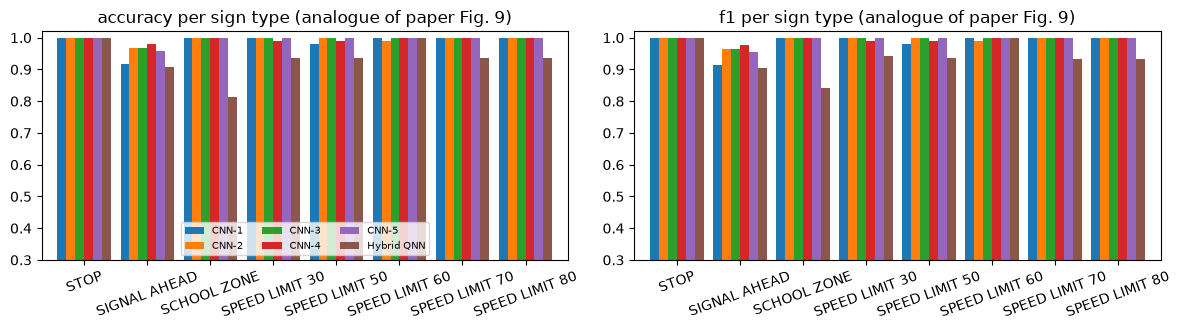

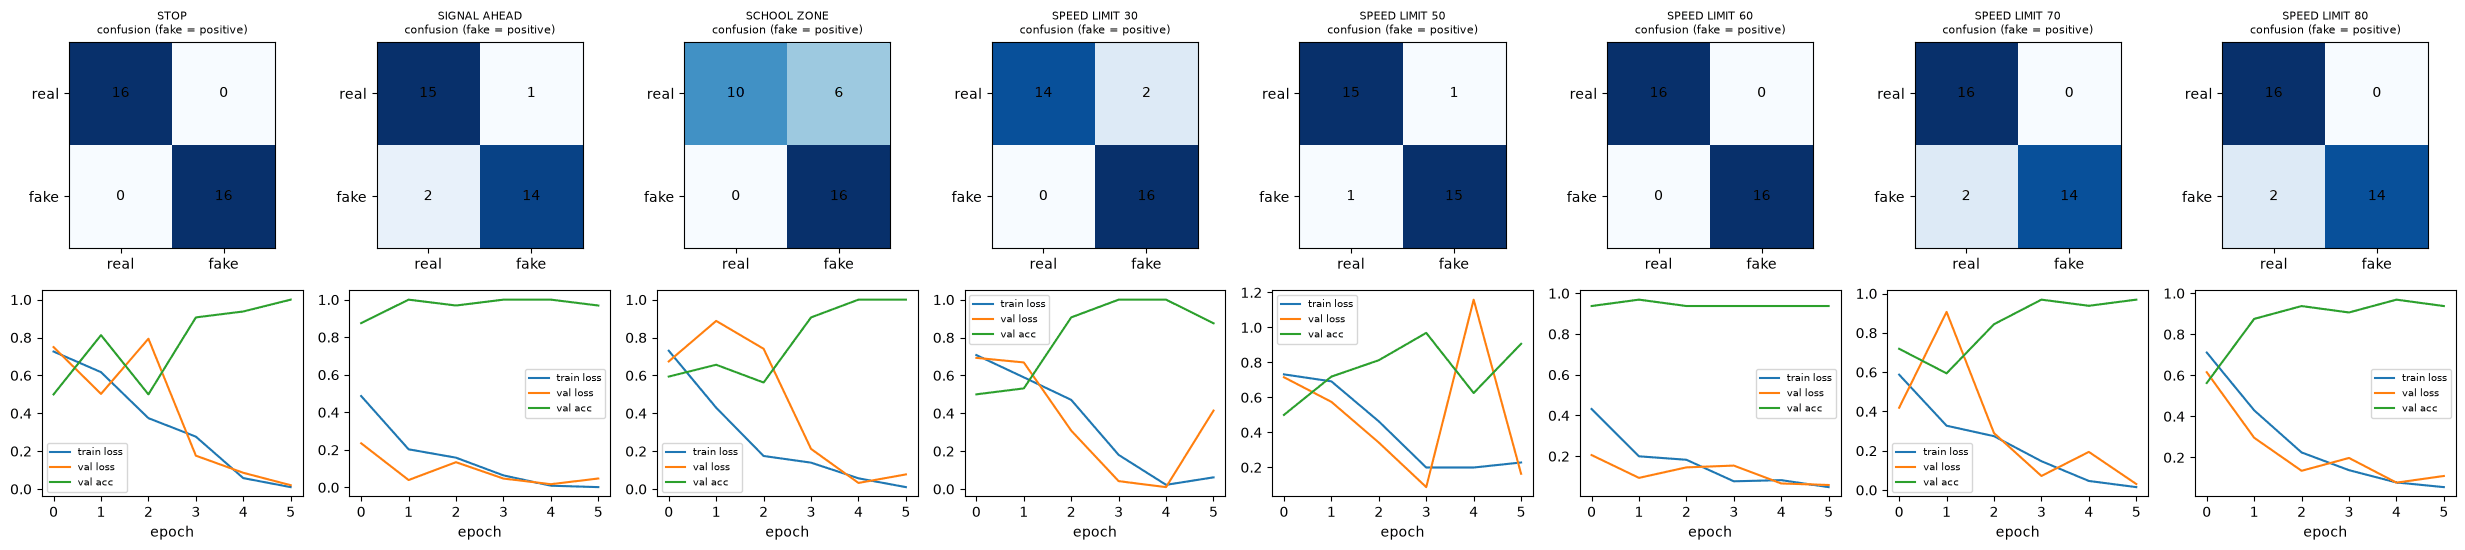

In [21]:

MODELS = [f"Classical CNN-{k}" for k in range(1, 6)] + ["Hybrid Quantum-Classical NN"]
SHORT = {m: ("Hybrid QNN" if m.startswith("Hybrid") else m.replace("Classical ", "")) for m in MODELS}
for metric in ("accuracy", "f1"):
    tab = R.groupby(["type", "model"])[metric].mean().unstack("model")[MODELS].loc[TYPES]
    tab.loc["MEAN over types"] = tab.mean()
    print(f"\n{metric.upper()} on the held-out test split (mean over seeds)"); display(tab.rename(columns=SHORT).round(3))
sd = R.groupby("model")["accuracy"].agg(["mean", "std", "count"]).loc[MODELS]
print("\nAccuracy over all (type, seed) runs: mean / std / runs"); display(sd.rename(index=SHORT).round(3))
tt = R.groupby("model")["train_time_s"].mean().loc[MODELS].rename(index=SHORT)
print("\nmean wall-clock training time per detector (s):"); display(tt.round(1).to_frame("seconds"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, metric in zip(axes, ("accuracy", "f1")):
    tab = R.groupby(["type", "model"])[metric].mean().unstack("model")[MODELS].loc[TYPES]
    tab.rename(columns=SHORT).plot.bar(ax=ax, rot=20, width=0.85, legend=False)
    ax.set_ylim(0.3, 1.02); ax.set_title(f"{metric} per sign type (analogue of paper Fig. 9)"); ax.set_xlabel("")
axes[0].legend(ncol=3, fontsize=7, loc="lower center")
plt.tight_layout(); plt.show()

hy = [r_ for r_ in results if r_["model"] == "Hybrid Quantum-Classical NN" and r_["seed"] == 0]
fig, axes = plt.subplots(2, max(1, len(hy)), figsize=(3.1 * len(hy), 5.6), squeeze=False)
for j, r_ in enumerate(hy):
    axes[0, j].imshow(r_["cm"], cmap="Blues"); axes[0, j].set_title(f"{r_['type']}\nconfusion (fake = positive)", fontsize=8)
    for (a, b), v in np.ndenumerate(r_["cm"]): axes[0, j].text(b, a, int(v), ha="center", va="center")
    axes[0, j].set_xticks([0, 1], ["real", "fake"]); axes[0, j].set_yticks([0, 1], ["real", "fake"])
    axes[1, j].plot(r_["hist"][:, 0], label="train loss"); axes[1, j].plot(r_["hist"][:, 1], label="val loss")
    axes[1, j].plot(r_["hist"][:, 2], label="val acc"); axes[1, j].set_xlabel("epoch"); axes[1, j].legend(fontsize=7)
plt.tight_layout(); plt.show()


## 10. Paper versus this notebook

Paper values for Fig. 9 are read off the bars (about +-0.01). The verdicts use the project rule: "reproduced" within 2 accuracy points, otherwise "not reached" or "exceeded"; "cannot be checked" when the notebook cannot measure the quantity.

In [22]:

# ---- numbers read off the paper's Fig. 9 bars (approximate, +-0.01) ----
PAPER_TYPES = ["STOP", "SIGNAL AHEAD", "PED XING", "SCHOOL ZONE", "SPEED LIMIT 25", "SPEED LIMIT 30",
               "SPEED LIMIT 35", "SPEED LIMIT 45", "SPEED LIMIT 55", "STOP AHEAD"]
PAPER_ACC = pd.DataFrame({
    "CNN-1": [.90, .98, .86, .93, .90, .85, .86, .91, .98, .96], "CNN-2": [.93, .98, .86, .93, .90, .88, .84, .98, .98, .96],
    "CNN-3": [.97, .98, .92, .95, .93, .92, .94, .98, .98, .96], "CNN-4": [1.0, .98, .94, .97, .93, .92, .94, .98, .98, .98],
    "CNN-5": [1.0, 1.0, 1.0, .97, .95, .92, .96, 1.0, 1.0, 1.0], "Hybrid QNN": [1.0, 1.0, .93, .98, .95, .93, .97, .90, .98, .98]},
    index=PAPER_TYPES)
mine_acc = R.groupby(["type", "model"])["accuracy"].mean().unstack("model")[MODELS].rename(columns=SHORT)
paper_mean, mine_mean = PAPER_ACC.mean(), mine_acc.mean()
print("Mean accuracy over sign types      paper (10 US types)   notebook (%d GTSRB types)" % len(TYPES))
display(pd.DataFrame({"paper": paper_mean, "notebook": mine_mean}).round(3).T)

same = [t for t in TYPES if t in PAPER_TYPES]            # sign types that exist in both studies
print("Types present in both studies:", same)
if same:
    display(pd.concat({"paper": PAPER_ACC.loc[same], "notebook": mine_acc.loc[same]}, axis=1).round(3))

def verdict(diff, tol=0.02):
    return "reproduced" if abs(diff) <= tol else ("exceeded (+%.3f)" % diff if diff > 0 else "not reached (%.3f)" % diff)

rows = []
# C1: Table 2 parameter counts (exact)
ok = bool(T2["identical"].all())
rows.append(("Table 2: parameter counts of all 6 models (17,346 / 27,778 / 97,794 / 391,426 / 1,571,586 / 5,425)",
             "6 values", f"{int(T2['identical'].sum())}/6 identical", "reproduced" if ok else "not reached"))
# C2: hybrid needs < 1/3 of CNN-1 memory
ratio = T2.loc["Hybrid Quantum-Classical NN", "notebook params"] / T2.loc["Classical CNN-1", "notebook params"]
rows.append(("Hybrid memory < 1/3 of the shallowest CNN (0.021 MB vs 0.066 MB)", "0.31", f"{ratio:.2f}", "reproduced" if ratio < 1 / 3 else "not reached"))
# C3: classical accuracy rises from CNN-1 to CNN-5
c1, c5 = mine_mean["CNN-1"], mine_mean["CNN-5"]
rows.append(("Classical accuracy improves with depth (mean acc CNN-1 -> CNN-5)", f"{paper_mean['CNN-1']:.3f} -> {paper_mean['CNN-5']:.3f}",
             f"{c1:.3f} -> {c5:.3f}", "reproduced" if c5 >= c1 - 0.02 and mine_mean["CNN-3"] >= c1 - 0.02 else "not reached"))
# C4: hybrid mean accuracy
rows.append(("Hybrid QNN mean test accuracy", f"{paper_mean['Hybrid QNN']:.3f}", f"{mine_mean['Hybrid QNN']:.3f}", verdict(mine_mean["Hybrid QNN"] - paper_mean["Hybrid QNN"])))
# C5: hybrid >= CNN-1..3 on most types
for k in (1, 2, 3):
    n_ge = int((mine_acc["Hybrid QNN"] >= mine_acc[f"CNN-{k}"] - 0.02).sum())
    pn = int((PAPER_ACC["Hybrid QNN"] >= PAPER_ACC[f"CNN-{k}"] - 0.02).sum())
    rows.append((f"Hybrid >= classical CNN-{k} (within 0.02) on most types", f"{pn}/10 types", f"{n_ge}/{len(TYPES)} types",
                 "reproduced" if n_ge / len(TYPES) >= 0.5 else "not reached"))
# C6: ResNet9 sign classifier
rows.append(("ResNet9 sign-type classifier accuracy (paper: on real + fake images)", "0.97", f"{R9_TEST_ACC:.3f} (real held-out only)", verdict(R9_TEST_ACC - 0.97)))
# C7: per-type values for the matching types
if same:
    d = (mine_acc.loc[same, "Hybrid QNN"] - PAPER_ACC.loc[same, "Hybrid QNN"])
    rows.append((f"Hybrid per-type accuracy for the shared types {same}", ", ".join(f"{v:.2f}" for v in PAPER_ACC.loc[same, "Hybrid QNN"]),
                 ", ".join(f"{v:.2f}" for v in mine_acc.loc[same, "Hybrid QNN"]), verdict(float(d.mean()))))
rows.append(("Deepfake attack fools the sign classifier (no number given)", "not reported",
             f"{(pred != ax_src).float().mean():.0%} of fakes read as another sign", "cannot be checked"))
rows.append(("Hybrid weaker on PED XING and SPEED LIMIT 45 (sign types not in this notebook)", "named exceptions", "-", "cannot be checked"))
CMP = pd.DataFrame(rows, columns=["Claim", "Paper", "Notebook", "Verdict"])
pd.set_option("display.max_colwidth", 90); display(CMP)
print(f"\nTotal notebook run time {(time.time()-T_NOTEBOOK)/60:.1f} min")


Mean accuracy over sign types      paper (10 US types)   notebook (8 GTSRB types)


,CNN-1,CNN-2,CNN-3,CNN-4,CNN-5,Hybrid QNN
paper,0.913,0.924,0.953,0.962,0.980,0.962
notebook,0.987,0.995,0.996,0.995,0.995,0.934


Types present in both studies: ['STOP', 'SIGNAL AHEAD', 'SCHOOL ZONE', 'SPEED LIMIT 30']


paper                                    notebook         \
               CNN-1 CNN-2 CNN-3 CNN-4 CNN-5 Hybrid QNN    CNN-1  CNN-2   
STOP            0.90  0.93  0.97  1.00  1.00       1.00    1.000  1.000   
SIGNAL AHEAD    0.98  0.98  0.98  0.98  1.00       1.00    0.917  0.969   
SCHOOL ZONE     0.93  0.93  0.95  0.97  0.97       0.98    1.000  1.000   
SPEED LIMIT 30  0.85  0.88  0.92  0.92  0.92       0.93    1.000  1.000   

                                                
                CNN-3  CNN-4  CNN-5 Hybrid QNN  
STOP            1.000  1.000  1.000      1.000  
SIGNAL AHEAD    0.969  0.979  0.958      0.906  
SCHOOL ZONE     1.000  1.000  1.000      0.812  
SPEED LIMIT 30  1.000  0.990  1.000      0.938

,Claim,Paper,Notebook,Verdict
0,"Table 2: parameter counts of all 6 models (17,346 / 27,778 / 97,794 / 391,426 / 1,571,...",6 values,6/6 identical,reproduced
1,Hybrid memory < 1/3 of the shallowest CNN (0.021 MB vs 0.066 MB),0.31,0.31,reproduced
2,Classical accuracy improves with depth (mean acc CNN-1 -> CNN-5),0.913 -> 0.980,0.987 -> 0.995,reproduced
3,Hybrid QNN mean test accuracy,0.962,0.934,not reached (-0.028)
4,Hybrid >= classical CNN-1 (within 0.02) on most types,10/10 types,3/8 types,not reached
5,Hybrid >= classical CNN-2 (within 0.02) on most types,9/10 types,2/8 types,not reached
6,Hybrid >= classical CNN-3 (within 0.02) on most types,9/10 types,2/8 types,not reached
7,ResNet9 sign-type classifier accuracy (paper: on real + fake images),0.97,0.969 (real held-out only),reproduced
8,"Hybrid per-type accuracy for the shared types ['STOP', 'SIGNAL AHEAD', 'SCHOOL ZONE', ...","1.00, 1.00, 0.98, 0.93","1.00, 0.91, 0.81, 0.94",not reached (-0.063)
9,Deepfake attack fools the sign classifier (no number given),not reported,90% of fakes read as another sign,cannot be checked



Total notebook run time 102.4 min


## 11. Reading the paper critically

* **The data are different.** GTSRB (German, low-resolution crops from video) replaces LISA + Mapillary. Absolute accuracies are therefore not comparable; the *relative* claims (hybrid vs CNN-1..5, parameter counts) are what can be checked.
* **The GAN here is weak.** A few hundred or thousand WGAN-GP iterations on CPU give blurry fakes; real-vs-fake detection of blurry fakes is easy, and fakes from a weak GAN often share artefacts, so a detector can generalise from train to test almost for free. The paper's GAN was trained far longer, and its fakes were cleaned by hand.
* **Near-duplicates inflate test scores.** We split real images by physical sign, but the fakes come from one generator and many look alike, so a few "new" test fakes are near-copies of training fakes. The paper does not say how it avoided this.
* **Tiny test sets.** 146 to 250 images per type means 30 to 50 test images, so a single image moves accuracy by 2 to 3 points. The paper's per-type bars (and ours) are not statistically separable; the paper reports a single run and no confidence interval.
* **"Memory" is parameter count.** The hybrid network has 5,425 parameters, but simulating it classically needs a 4096-amplitude complex state for each of the 32 circuits and each image, and a real quantum computer would need 12 noise-free qubits and amplitude encoding of every image, which costs a deep state-preparation circuit that the paper does not discuss. The memory saving is real only for the stored weights.
* **Amplitude encoding is non-trivial.** After normalisation the encoded state of a natural image is dominated by overall brightness; the circuit is a quantum-kernel-like quadratic form of the normalised image, which explains why 5,425 parameters can work, but it also means colour or brightness artefacts of the GAN may be what is detected.
* **Pipeline coupling.** The detector is only used after the sign classifier names the type, so classifier errors on fakes (which the attacker explicitly optimises for) route images to the wrong detector; the paper reports the 0.97 classifier figure on the combined set but not the end-to-end detection rate.

## 12. Exercises

1. Set `N_PER_TYPE` to 400 in the full configuration and see whether the hybrid network still matches CNN-3. Why do more images help the CNNs more than the 5,425-parameter hybrid network?
2. Replace amplitude encoding by angle encoding on 12 PCA features of the image (compare with the paper's cited angle-encoding approach). How do accuracy and simulation time change?
3. Train the GAN for 5x more iterations (`GAN_ITERS`). Do the CNN detectors get worse, i.e. are better fakes harder to detect? Does the hybrid network react differently?
4. Change `N_CIRCUITS` from 32 to 8 and 64. How does the parameter count (and Eq. 6 memory) trade against accuracy?
5. Remove the brickwork odd layer in `brick` (keep only the even pairs). Does the quantum NN lose accuracy, and why might entanglement between neighbouring blocks matter?